# FarmTech Solutions - Visão Computacional com YOLOv5 (Entrega 1)
**Grupo:** Deweyne (rm573755), Jeliel (rm572665), Denis (rm573278)

## Contexto
A FarmTech Solutions está expandindo seus serviços de IA para além do agronegócio (saúde animal, segurança patrimonial, controle de acesso, análise de documentos e visão computacional). Este notebook demonstra a um cliente, **na prática**, como um sistema de visão computacional é construído, treinado e avaliado, mostrando seu potencial e sua acurácia.

## O que foi feito
Treinamos o **YOLOv5s** (*fine-tuning* sobre pesos pré-treinados) para detectar dois objetos bem diferentes entre si: **cadeiras** (`chair`) e **garrafas** (`bottle`). Para estudar o efeito do tempo de treino, repetimos o mesmo experimento com **30, 60 e 90 épocas** e comparamos precisão, erro e desempenho.

## Dataset
80 imagens no total, 40 de cada classe, divididas **por classe** em 32 treino / 4 validação / 4 teste (64 / 8 / 8 no total). Todas as imagens foram rotuladas manualmente no **Make Sense** (formato YOLO) e ficam no Google Drive.

## Sumário
0. Ambiente (GPU e Google Drive)
1. Preparação e checagem do dataset
2. Treinamento (30, 60 e 90 épocas)
3. Curvas de treinamento
4. Validação e teste (métricas, por classe e tempo de inferência)
5. Imagens de teste processadas pelos modelos
6. Conclusões

## 0. Ambiente
Redes neurais de visão computacional exigem muito processamento paralelo, por isso o treino roda em **GPU**. Antes de começar, confirmamos que o Colab está com GPU ativa (*Ambiente de execução > Alterar tipo de ambiente de execução > T4 GPU*) e registramos as versões usadas, o que ajuda na reprodutibilidade do experimento.

In [1]:
# Mostra a GPU alocada pelo Colab e as versões das bibliotecas principais
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch, sys
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| GPU disponível:', torch.cuda.is_available())

name, memory.total [MiB]
Tesla T4, 15360 MiB
Python: 3.13.15 | PyTorch: 2.11.0+cu130 | GPU disponível: True


In [2]:
# Monta o Google Drive: é de lá que lemos o dataset e é para lá que salvamos todos os resultados
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Preparação e checagem do dataset
Nesta etapa vamos: (1) definir os caminhos, (2) clonar o repositório oficial do **YOLOv5 (Ultralytics)** e instalar suas dependências, e (3) **verificar a qualidade do dataset antes de treinar**. Erros de rotulação (classe trocada, imagem sem `.txt`, caixa fora do lugar) são a causa mais comum de resultado ruim em detecção de objetos, e é muito mais barato detectá-los agora do que depois de treinar.

O dataset é lido **diretamente do Google Drive**. Os resultados (pesos, gráficos, imagens detectadas) também são gravados no Drive, então não se perdem se a sessão do Colab cair.

In [3]:
import os, shutil, time, json, re, subprocess, glob
os.environ.setdefault('WANDB_MODE', 'disabled')  # evita solicitação de login durante os treinos

# ---- Caminhos principais (ajuste DRIVE_DS se a pasta estiver em outro lugar) ----
DRIVE_DS = '/content/drive/MyDrive/Farmtech_YOLO'   # dataset no Drive (images/ e labels/ com train, val e test)
RUNS_DIR = f'{DRIVE_DS}/runs'                       # onde ficam os resultados de treino, validação e detecção
os.makedirs(RUNS_DIR, exist_ok=True)

# ---- Classes: a ORDEM define o id (0, 1) e deve ser a mesma usada no Make Sense ----
CLASSES = ['chair', 'bottle']                       # id 0 = chair, id 1 = bottle

# ---- Clona o YOLOv5 (só se ainda não existir) e instala as dependências ----
if not os.path.exists('/content/yolov5'):
    !git clone -q https://github.com/ultralytics/yolov5 /content/yolov5
%cd /content/yolov5
!pip install -q -r requirements.txt


/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 503.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 10.0 MB/s eta 0:00:00


In [4]:
# Mantém compatibilidade com os arquivos .cfg/.weights da YOLOv3 tradicional
import sys, subprocess

subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '-q', 'opencv-python-headless==4.10.0.84'],
    check=True
)
print('OpenCV 4 instalado para uso da YOLOv3 tradicional na Entrega 2.')


OpenCV 4 instalado para uso da YOLOv3 tradicional na Entrega 2.


In [5]:
# Confere a quantidade de imagens e labels em cada conjunto e se TODA imagem tem o .txt correspondente
EXT_IMG = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')
for split in ['train', 'val', 'test']:
    imgs = [f for f in os.listdir(f'{DRIVE_DS}/images/{split}') if f.lower().endswith(EXT_IMG)]
    lbls = [f for f in os.listdir(f'{DRIVE_DS}/labels/{split}') if f.endswith('.txt')]
    sem_label = sorted(set(os.path.splitext(f)[0] for f in imgs) - set(os.path.splitext(f)[0] for f in lbls))
    print(f'{split:5s} -> {len(imgs)} imagens | {len(lbls)} labels | imagens sem label: {sem_label if sem_label else "nenhuma"}')

# Remove caches antigos de labels (o YOLOv5 recria sozinho; evita usar um cache desatualizado se algum label mudou)
for c in glob.glob(f'{DRIVE_DS}/labels/*.cache'):
    os.remove(c)

train -> 64 imagens | 64 labels | imagens sem label: nenhuma
val   -> 8 imagens | 8 labels | imagens sem label: nenhuma
test  -> 8 imagens | 8 labels | imagens sem label: nenhuma


In [6]:
# Conta quantas caixas (objetos rotulados) existem por classe em cada conjunto
from collections import Counter
for split in ['train', 'val', 'test']:
    cont = Counter()
    for f in os.listdir(f'{DRIVE_DS}/labels/{split}'):
        for linha in open(f'{DRIVE_DS}/labels/{split}/{f}'):
            if linha.strip():
                cont[int(linha.split()[0])] += 1
    nomes = {(CLASSES[k] if k < len(CLASSES) else f'id {k} (INVÁLIDO)'): v for k, v in sorted(cont.items())}
    print(f'{split:5s} -> caixas por classe: {nomes}')

train -> caixas por classe: {'chair': 40, 'bottle': 44}
val   -> caixas por classe: {'chair': 6, 'bottle': 4}
test  -> caixas por classe: {'chair': 9, 'bottle': 6}


### Verificação visual dos rótulos
Cada `.txt` do formato YOLO tem uma linha por objeto: `id_da_classe x_centro y_centro largura altura`, com valores **normalizados** entre 0 e 1. Abaixo desenhamos as caixas sobre algumas imagens de treino. Se as caixas estiverem justas e os nomes das classes corretos (cadeiras como `chair`, garrafas como `bottle`), a **ordem das classes** e a rotulação estão certas.

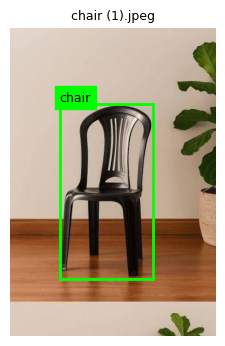

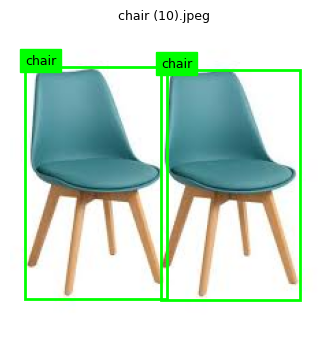

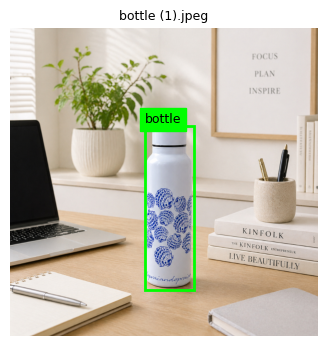

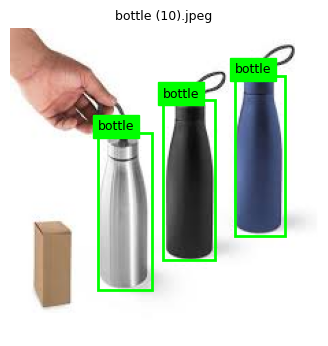

In [7]:
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

def mostrar_com_labels(prefixo, n=2, split='train'):
    # Desenha as caixas rotuladas sobre as n primeiras imagens do conjunto cujo nome começa com 'prefixo'
    arqs = sorted(f for f in os.listdir(f'{DRIVE_DS}/images/{split}') if f.startswith(prefixo))[:n]
    for a in arqs:
        img = Image.open(f'{DRIVE_DS}/images/{split}/{a}').convert('RGB')
        W, H = img.size
        fig, ax = plt.subplots(figsize=(4, 4))
        ax.imshow(img); ax.axis('off')
        lbl = f'{DRIVE_DS}/labels/{split}/{os.path.splitext(a)[0]}.txt'
        for linha in open(lbl):
            if not linha.strip():
                continue
            c, xc, yc, w, h = linha.split()
            c = int(c); xc, yc, w, h = (float(v) for v in (xc, yc, w, h))
            # converte de coordenadas normalizadas (centro, largura, altura) para pixels (canto superior esquerdo)
            x0, y0 = (xc - w/2) * W, (yc - h/2) * H
            ax.add_patch(patches.Rectangle((x0, y0), w*W, h*H, fill=False, edgecolor='lime', linewidth=2))
            ax.text(x0, y0, CLASSES[c], color='black', backgroundcolor='lime', fontsize=9, va='bottom')
        ax.set_title(a, fontsize=9)
        plt.show()

mostrar_com_labels('chair', n=2)
mostrar_com_labels('bottle', n=2)

### Arquivo `data.yaml`
É o "mapa" do dataset para o YOLOv5: informa onde estão as imagens de treino, validação e teste e quais são as classes. O YOLOv5 encontra os labels sozinho, trocando `/images/` por `/labels/` no caminho de cada imagem. **A ordem em `names` precisa ser a mesma usada na criação das classes no Make Sense** (id 0 = primeira classe criada).

In [8]:
# Cria o data.yaml apontando para o dataset no Drive
yaml_txt = f'''path: {DRIVE_DS}
train: images/train
val: images/val
test: images/test
nc: {len(CLASSES)}
names: {CLASSES}
'''
with open('/content/data.yaml', 'w') as f:
    f.write(yaml_txt)
print(yaml_txt)

path: /content/drive/MyDrive/Farmtech_YOLO
train: images/train
val: images/val
test: images/test
nc: 2
names: ['chair', 'bottle']



## 2. Treinamento
### Estratégia: *transfer learning*
Treinar uma rede de detecção do zero exigiria milhares de imagens. Com apenas 64 imagens de treino, partimos do **YOLOv5s** (versão *small*, leve e rápida) já pré-treinado no dataset COCO. Ele já "sabe enxergar" bordas, texturas e formas; nós apenas o **ajustamos (*fine-tuning*)** para as nossas duas classes.

### O que é uma época?
Uma **época** é uma passagem completa por todas as imagens de treino. Poucas épocas deixam o modelo **subajustado** (*underfitting*, não aprendeu o suficiente); épocas demais podem causar **sobreajuste** (*overfitting*, decora o treino e generaliza mal). Por isso executamos **três simulações idênticas, mudando apenas o número de épocas: 30, 60 e 90**.

### Parâmetros usados (iguais nas três simulações)
| Parâmetro | Valor | Significado |
|---|---|---|
| `--weights` | `yolov5s.pt` | ponto de partida: pesos pré-treinados no COCO |
| `--img` | 640 | as imagens são redimensionadas para 640 px no maior lado |
| `--batch` | 16 | imagens processadas por vez antes de atualizar os pesos |
| `--epochs` | 30 / 60 / 90 | **única variável do experimento** |
| `--cache` | `ram` | guarda as imagens na memória após a 1ª época (o Drive é lento para leituras repetidas) |
| `--seed` | 0 (padrão) | semente aleatória fixa, para reduzir a variação entre execuções |

Os demais hiperparâmetros (taxa de aprendizado, *data augmentation* automático etc.) ficam nos valores padrão do YOLOv5.

### Como o erro (*loss*) é medido
O YOLOv5 soma três perdas: **`box_loss`** (quão bem a caixa prevista cobre o objeto), **`obj_loss`** (se existe um objeto naquela posição) e **`cls_loss`** (se a classe está correta). Quanto menor, melhor. O treino também grava a cada época as métricas no conjunto de validação e guarda dois arquivos de pesos: `last.pt` (última época) e **`best.pt`** (a melhor época segundo a métrica *fitness* = 10% mAP@0.5 + 90% mAP@0.5:0.95). Usaremos o `best.pt` nas avaliações.

### Tempo de treino
Medimos o tempo total de cada simulação (inclui a preparação inicial do treino, então o tempo não cresce de forma exatamente proporcional às épocas) e salvamos em um arquivo no Drive.

In [9]:
# Nomes das simulações e arquivo no Drive onde guardamos o tempo de treino de cada uma
MODELOS = ['treino_30ep', 'treino_60ep', 'treino_90ep']
ARQ_TEMPOS = f'{RUNS_DIR}/tempos_treino.json'
tempos = json.load(open(ARQ_TEMPOS)) if os.path.exists(ARQ_TEMPOS) else {}   # recarrega tempos de execuções anteriores

# Se os pesos já existem no Drive, o treino é PULADO (evita retreinar sem querer e mudar os resultados já analisados).
# Para retreinar do zero, mude para True. Em um Drive sem pesos (primeira execução), o treino acontece normalmente.
FORCAR_RETREINO = False

def treinar(epocas, nome):
    # Treina o YOLOv5s por 'epocas' épocas e devolve o tempo total gasto (segundos)
    destino = f'{RUNS_DIR}/{nome}'
    if os.path.exists(f'{destino}/weights/best.pt') and nome in tempos and not FORCAR_RETREINO:
        print(f'[{nome}] pesos já existem no Drive: treino pulado (tempo registrado na execução original).')
        return tempos[nome]
    if os.path.exists(destino):
        shutil.rmtree(destino)    # apaga rodada anterior: sem isso o results.csv é ACUMULADO e as curvas ficam erradas
    t0 = time.time()
    !python train.py --img 640 --batch 16 --epochs {epocas} --data /content/data.yaml \
        --weights yolov5s.pt --cache ram --project {RUNS_DIR} --name {nome} --exist-ok
    seg = time.time() - t0
    tempos[nome] = round(seg, 1)                  # guarda o tempo e persiste no Drive
    json.dump(tempos, open(ARQ_TEMPOS, 'w'))
    return seg

### Simulação 1: 30 épocas
Treino curto, serve de **linha de base**: mostra o que o modelo consegue aprender com pouco tempo.

In [10]:
seg = treinar(30, 'treino_30ep')
print(f'Tempo total (30 épocas): {seg/60:.1f} min')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791861803.887462    4698 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=/cont

### Simulação 2: 60 épocas
Dobramos o tempo de treino mantendo todo o resto igual.

In [11]:
seg = treinar(60, 'treino_60ep')
print(f'Tempo total (60 épocas): {seg/60:.1f} min')

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791861965.813930    5494 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=/content/drive/MyDrive/Farmtech_YOLO/runs, name=treino_60ep, exist_ok=True, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: up to date with https://github.com/ultralytics/yol

### Simulação 3: 90 épocas
Treino mais longo, para verificar se ainda há ganho ou se o modelo já estabilizou (retorno decrescente).

In [12]:
seg = treinar(90, 'treino_90ep')
print(f'Tempo total (90 épocas): {seg/60:.1f} min')

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791862120.197255    6231 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=90, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=/content/drive/MyDrive/Farmtech_YOLO/runs, name=treino_90ep, exist_ok=True, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: up to date with https://github.com/ultralytics/yol

## 3. Curvas de treinamento
O arquivo `results.csv` de cada simulação guarda, época a época, os erros e as métricas de validação. Observe:
- **Erro de treino x erro de validação:** os dois devem cair. Se o de treino continua caindo mas o de validação para ou sobe, há sinal de **sobreajuste**.
- **mAP@0.5 e mAP@0.5:0.95 na validação:** devem subir e estabilizar. O ponto onde a curva "achata" indica quando mais épocas deixam de compensar.

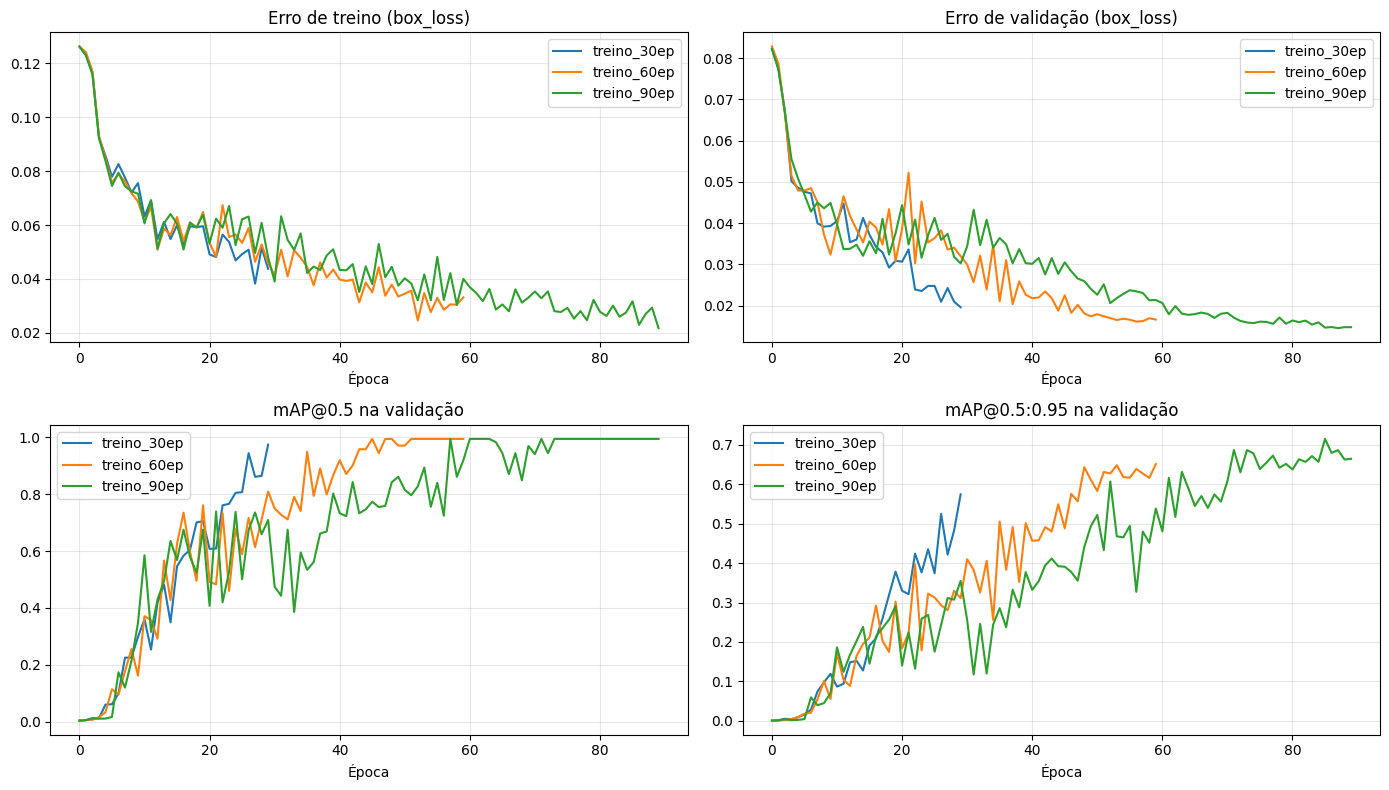

In [13]:
import pandas as pd

# Lê o results.csv de cada simulação (os nomes das colunas vêm com espaços extras, por isso o strip)
res = {}
for nome in MODELOS:
    df = pd.read_csv(f'{RUNS_DIR}/{nome}/results.csv')
    df.columns = df.columns.str.strip()
    assert not df['epoch'].duplicated().any(), f'{nome}: results.csv tem épocas repetidas (rode o treino de novo)'
    res[nome] = df

# Gráficos comparando as três simulações
graficos = [('train/box_loss', 'Erro de treino (box_loss)'),
            ('val/box_loss', 'Erro de validação (box_loss)'),
            ('metrics/mAP_0.5', 'mAP@0.5 na validação'),
            ('metrics/mAP_0.5:0.95', 'mAP@0.5:0.95 na validação')]
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
for ax, (col, titulo) in zip(axs.ravel(), graficos):
    for nome, df in res.items():
        ax.plot(df['epoch'], df[col], label=nome)
    ax.set_title(titulo); ax.set_xlabel('Época'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 4. Validação e Teste
- **Validação** (`val`: 4 cadeiras + 4 garrafas): usada **durante** o treino para escolher o `best.pt`. Como ela influencia a escolha do modelo, suas métricas tendem a ser **otimistas**.
- **Teste** (`test`: 4 cadeiras + 4 garrafas): imagens que o modelo **nunca viu** nem usou para escolher pesos. É a medida honesta da capacidade de generalização, e a que usamos para convencer o cliente.

### Métricas
- **Precisão:** das detecções que o modelo fez, quantas estavam corretas (poucos falsos alarmes).
- **Recall:** dos objetos que realmente existiam, quantos o modelo encontrou (poucos objetos perdidos).
- **IoU:** sobreposição entre a caixa prevista e a caixa rotulada. Uma detecção só conta como acerto se o IoU passar de um limiar.
- **mAP@0.5:** média da precisão sobre as classes, aceitando acerto com IoU ≥ 0.5 (critério mais permissivo).
- **mAP@0.5:0.95:** média sobre IoU de 0.5 a 0.95 (critério rígido: premia caixas bem ajustadas ao objeto).

Rodamos o `val.py` do YOLOv5 em cada modelo, nos dois conjuntos, e extraímos as métricas (geral e por classe) da saída.

In [14]:
def avaliar(nome, task):
    # Roda o val.py do YOLOv5 no conjunto 'task' (val ou test) usando o best.pt do modelo 'nome'.
    # Devolve uma lista de dicts com as métricas gerais ('all') e de cada classe.
    cmd = ['python', 'val.py', '--weights', f'{RUNS_DIR}/{nome}/weights/best.pt',
           '--data', '/content/data.yaml', '--task', task, '--img', '640', '--verbose',
           '--project', f'{RUNS_DIR}/val_{task}', '--name', nome, '--exist-ok']
    out = subprocess.run(cmd, capture_output=True, text=True)
    txt = out.stdout + out.stderr
    # Linhas do tipo: "<classe>  <imagens>  <instâncias>  P  R  mAP50  mAP50-95"
    padrao = r'^\s*(' + '|'.join(['all'] + CLASSES) + r')\s+(\d+)\s+(\d+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)'
    achados = {}
    for m in re.finditer(padrao, txt, re.M):
        achados[m.group(1)] = m          # guarda a última ocorrência de cada classe
    if 'all' not in achados:
        raise RuntimeError('Não consegui ler as métricas do val.py. Final da saída:\n' + txt[-1500:])
    return [{'Modelo': nome, 'Conjunto': task, 'Classe': c, 'Instâncias': int(m.group(3)),
             'Precisão': float(m.group(4)), 'Recall': float(m.group(5)),
             'mAP@0.5': float(m.group(6)), 'mAP@0.5:0.95': float(m.group(7))}
            for c, m in achados.items()]

# Avalia as 3 simulações na validação e no teste
linhas = []
for nome in MODELOS:
    for task in ['val', 'test']:
        linhas += avaliar(nome, task)
df_all = pd.DataFrame(linhas)

### Resultado geral (todas as classes)
Tabela principal da Entrega 1: métricas de validação e teste para 30, 60 e 90 épocas, junto com o tempo de treino de cada simulação.

In [15]:
# Tabela geral (linha 'all') + tempo de treino de cada simulação
tabela = df_all[df_all['Classe'] == 'all'].drop(columns=['Classe', 'Instâncias']).reset_index(drop=True)
tabela['Tempo de treino (min)'] = tabela['Modelo'].map(lambda n: round(tempos[n] / 60, 1))
tabela.round(3)

,Modelo,Conjunto,Precisão,Recall,mAP@0.5,mAP@0.5:0.95,Tempo de treino (min)
0,treino_30ep,val,0.858,0.884,0.975,0.574,2.8
1,treino_30ep,test,0.846,0.620,0.741,0.358,2.8
2,treino_60ep,val,0.962,0.978,0.995,0.629,2.6
3,treino_60ep,test,0.974,0.761,0.828,0.535,2.6
4,treino_90ep,val,0.944,0.988,0.995,0.715,3.5
5,treino_90ep,test,0.880,0.744,0.779,0.492,3.5


### Resultado por classe (conjunto de teste)
Mostra se o modelo tem desempenho parecido nas duas classes ou se erra mais em uma delas.

In [16]:
# Métricas por classe, apenas no conjunto de teste
por_classe = df_all[(df_all['Conjunto'] == 'test') & (df_all['Classe'] != 'all')].reset_index(drop=True)
por_classe.round(3)

,Modelo,Conjunto,Classe,Instâncias,Precisão,Recall,mAP@0.5,mAP@0.5:0.95
0,treino_30ep,test,chair,9,1.000,0.739,0.946,0.538
1,treino_30ep,test,bottle,6,0.693,0.500,0.537,0.177
2,treino_60ep,test,chair,9,1.000,0.855,0.984,0.656
3,treino_60ep,test,bottle,6,0.947,0.667,0.672,0.414
4,treino_90ep,test,chair,9,1.000,0.988,0.995,0.669
5,treino_90ep,test,bottle,6,0.761,0.500,0.564,0.314


### Tempo de inferência (predição)
O `val.py` mede a velocidade com poucas imagens e inclui o aquecimento da GPU, então o valor varia bastante entre execuções (o mesmo modelo pode aparecer com 12 ms numa rodada e 30 ms em outra). Para uma medida confiável fazemos nossa própria medição: carregamos as imagens de teste na memória (para não medir a leitura do Drive), fazemos **3 passadas de aquecimento** e depois **20 repetições** sobre as imagens de teste, **uma imagem por vez** (como seria numa aplicação real). O tempo inclui pré-processamento, rede neural e supressão de caixas duplicadas (NMS).

In [17]:
import torch

def medir_inferencia(nome, n_rep=20, tam=640):
    # Devolve (média, desvio padrão) do tempo de inferência em ms/imagem para o modelo 'nome'
    modelo = torch.hub.load('/content/yolov5', 'custom', path=f'{RUNS_DIR}/{nome}/weights/best.pt', source='local')
    modelo.conf = 0.25
    imgs = [Image.open(p).convert('RGB') for p in sorted(glob.glob(f'{DRIVE_DS}/images/test/*'))]   # imagens já na RAM
    sync = torch.cuda.synchronize if torch.cuda.is_available() else (lambda: None)                    # espera a GPU terminar
    for _ in range(3):
        for im in imgs: modelo(im, size=tam)                 # aquecimento (não entra na medição)
    medidas = []
    for _ in range(n_rep):
        sync(); t0 = time.perf_counter()
        for im in imgs: modelo(im, size=tam)                 # uma imagem por vez (batch = 1)
        sync()
        medidas.append((time.perf_counter() - t0) / len(imgs) * 1000)
    return float(np.mean(medidas)), float(np.std(medidas))

import numpy as np
inf = {n: medir_inferencia(n) for n in MODELOS}
tab_inf = pd.DataFrame([{'Modelo': n, 'Inferência média (ms/img)': m, 'Desvio (ms)': s} for n, (m, s) in inf.items()])
tab_inf.round(2)

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 


,Modelo,Inferência média (ms/img),Desvio (ms)
0,treino_30ep,13.95,1.04
1,treino_60ep,11.24,2.51
2,treino_90ep,10.07,0.49


### Quadro-resumo (conjunto de teste)
Reúne em uma única tabela tudo o que será usado nas conclusões e, depois, na **comparação com as outras abordagens da Entrega 2** (YOLO padrão e CNN do zero). A tabela também é salva em CSV no Drive.

In [18]:
# Quadro-resumo: métricas de teste + tempo de treino + tempo de inferência
resumo = (tabela[tabela['Conjunto'] == 'test']
          .merge(tab_inf, on='Modelo')
          .drop(columns=['Conjunto'])
          .set_index('Modelo'))
resumo.to_csv(f'{RUNS_DIR}/resumo_entrega1.csv')   # guarda para reutilizar na Entrega 2
resumo.round(3)

,Precisão,Recall,mAP@0.5,mAP@0.5:0.95,Tempo de treino (min),Inferência média (ms/img),Desvio (ms)
Modelo,,,,,,,
treino_30ep,0.846,0.620,0.741,0.358,2.8,13.954,1.043
treino_60ep,0.974,0.761,0.828,0.535,2.6,11.238,2.514
treino_90ep,0.880,0.744,0.779,0.492,3.5,10.065,0.493


## 5. Imagens de teste processadas pelos modelos
O `detect.py` aplica o modelo treinado às imagens de teste e desenha, sobre cada objeto encontrado, a **caixa**, a **classe** e a **confiança** (de 0 a 1). Só são mostradas detecções com confiança ≥ 0.25. O YOLOv5 informa o destino dos arquivos na linha `Results saved to ...` (aqui, na pasta `runs/detect` do Drive).

Abaixo, a mesma imagem processada pelos três modelos, lado a lado (30, 60 e 90 épocas), para observar se mais épocas geram caixas mais ajustadas, confianças mais altas e menos erros (falsos positivos ou objetos perdidos).

In [19]:
# Roda a detecção nas imagens de teste com os três modelos
for nome in MODELOS:
    !python detect.py --weights {RUNS_DIR}/{nome}/weights/best.pt --source {DRIVE_DS}/images/test \
        --img 640 --conf-thres 0.25 --project {RUNS_DIR}/detect --name {nome} --exist-ok

detect: weights=['/content/drive/MyDrive/Farmtech_YOLO/runs/treino_30ep/weights/best.pt'], source=/content/drive/MyDrive/Farmtech_YOLO/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/drive/MyDrive/Farmtech_YOLO/runs/detect, name=treino_30ep, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/drive/MyDrive/Farmtech_YOLO/images/test/bottle (37).jpeg: 640x448 4 bottles, 31.7ms
image 2/8 /content/drive/MyDrive/Farmtech_YOLO/images/test/bottle (38).jpeg: 640x448 1 chair, 1 bottle, 13.1ms
ima

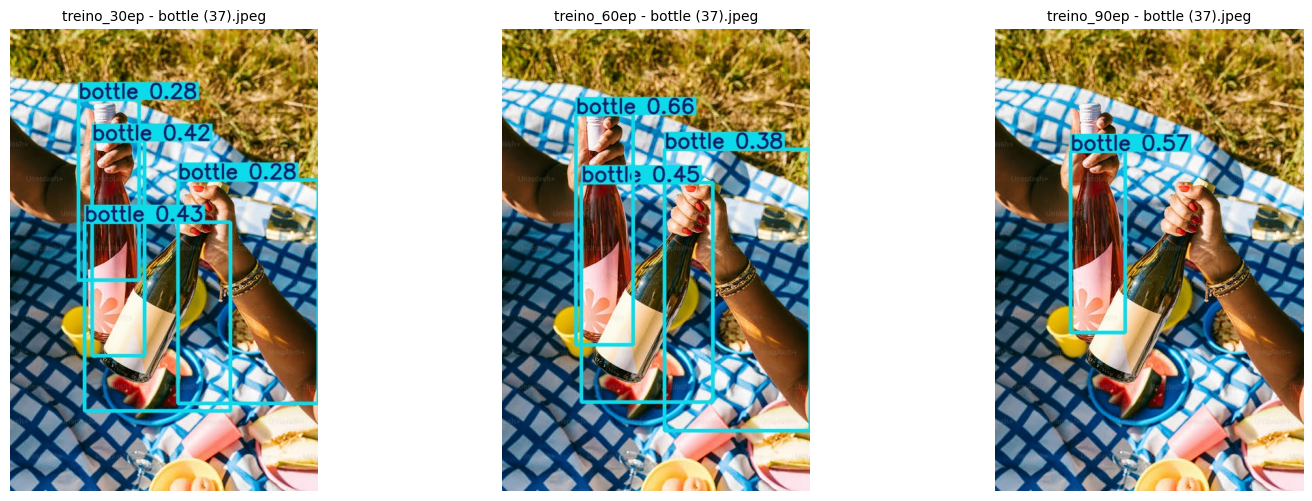

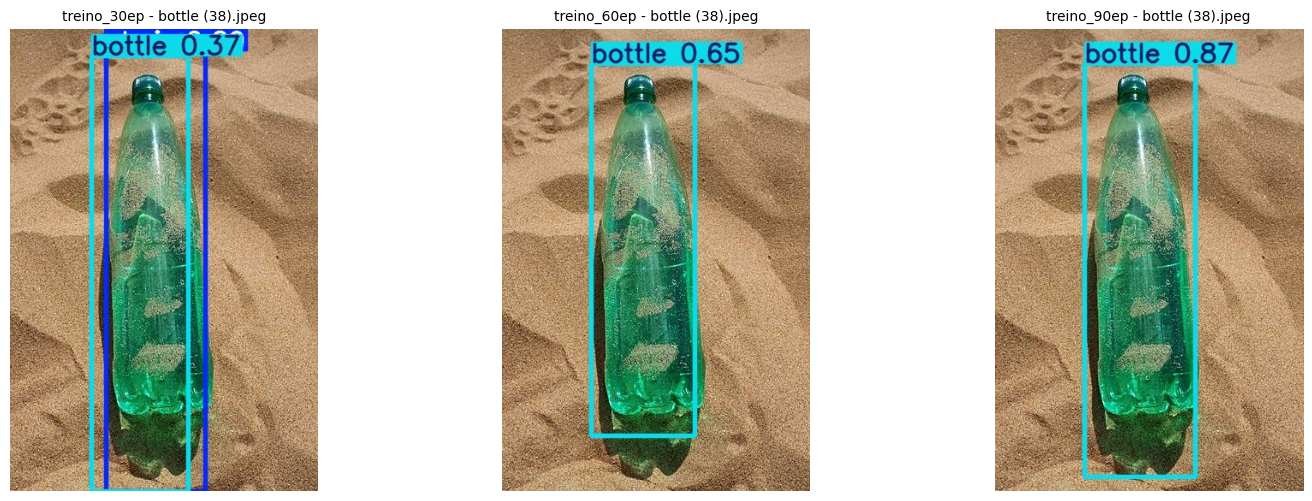

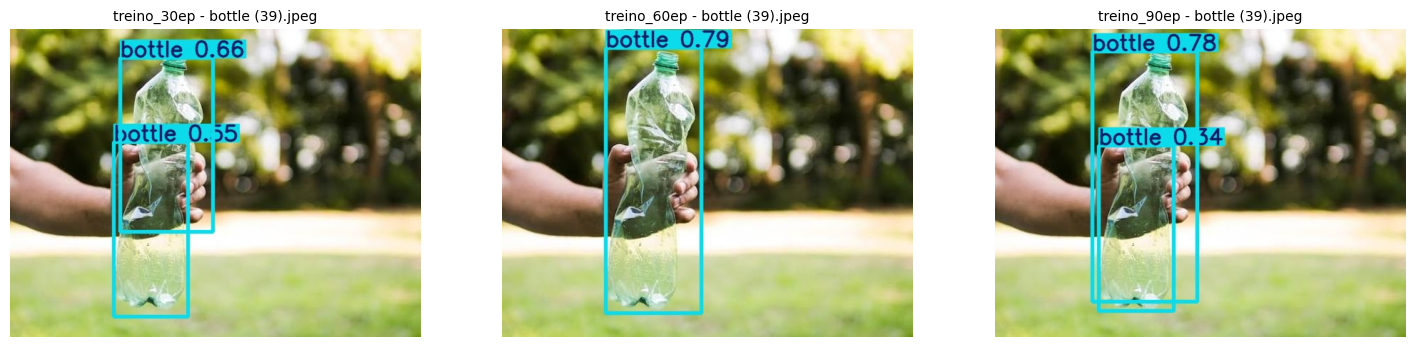

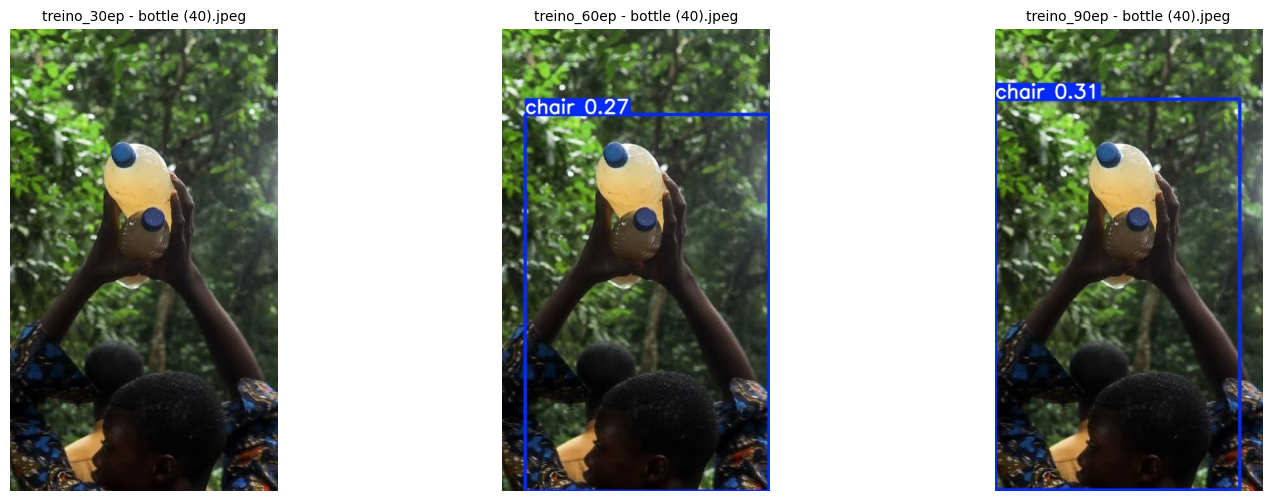

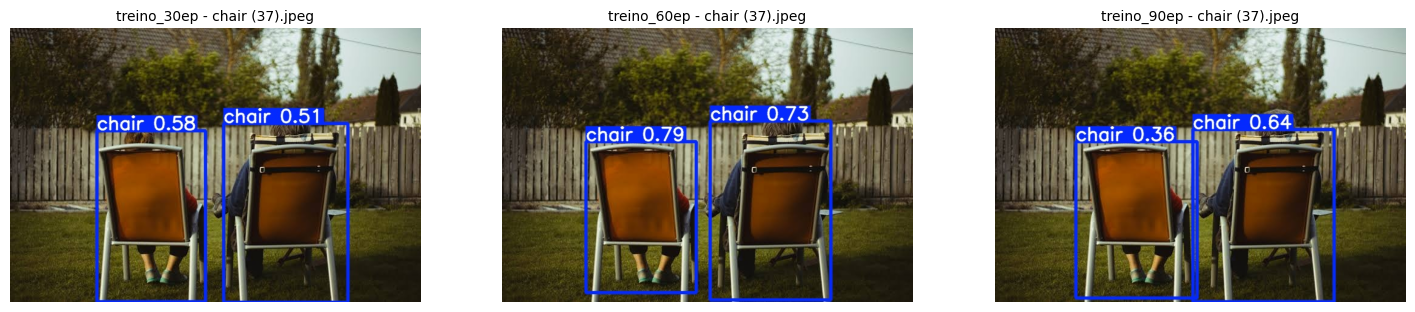

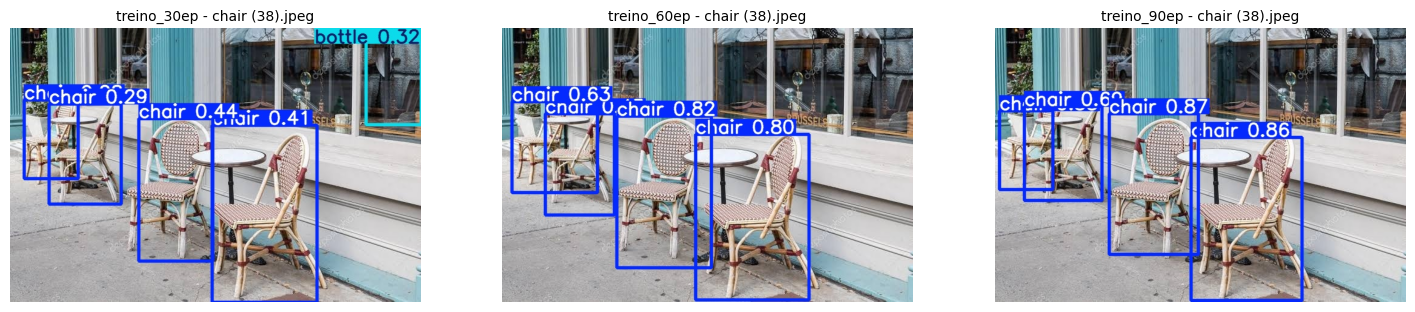

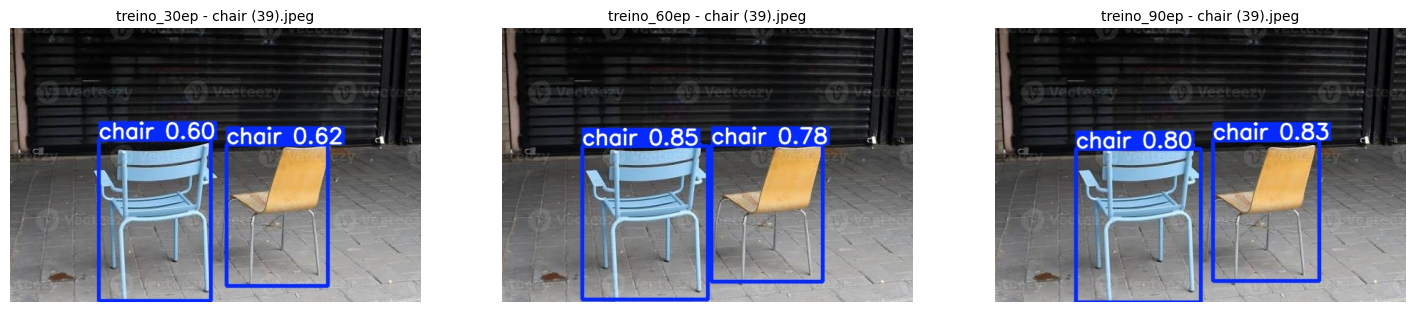

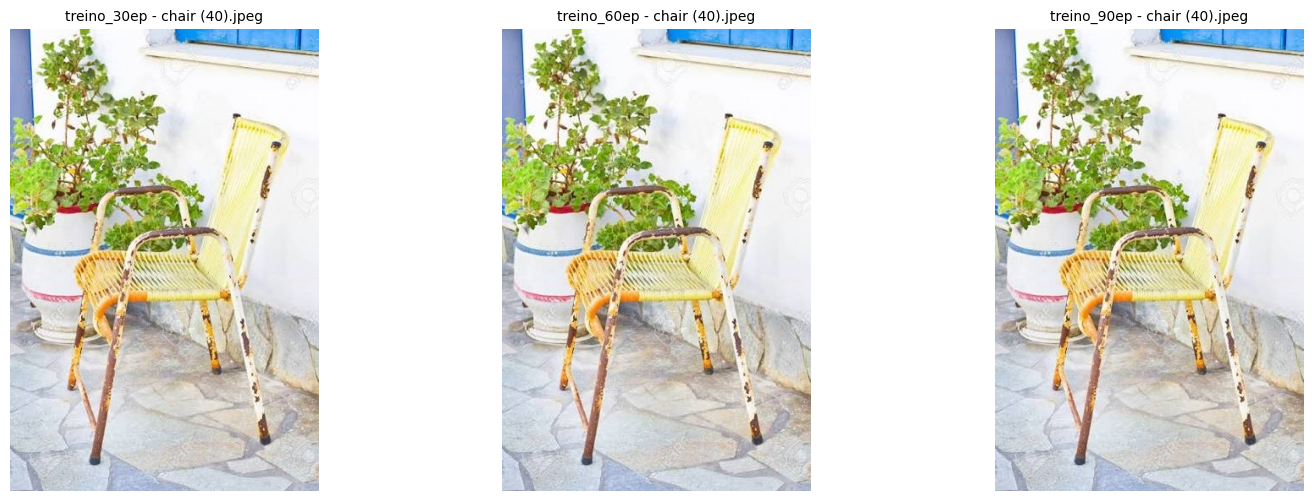

In [20]:
# Exibe cada imagem de teste processada pelos três modelos, lado a lado
import matplotlib.image as mpimg
arqs = sorted(os.listdir(f'{RUNS_DIR}/detect/{MODELOS[0]}'))
for a in arqs:
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))
    for ax, nome in zip(axs, MODELOS):
        ax.imshow(mpimg.imread(f'{RUNS_DIR}/detect/{nome}/{a}'))
        ax.set_title(f'{nome} - {a}', fontsize=10); ax.axis('off')
    plt.show()

### Matriz de confusão (teste)
Mostra, para cada classe real (colunas), o que o modelo previu (linhas). A diagonal são os acertos. A categoria `background` indica **objetos não detectados** (linha de previsão `background`) ou **falsos alarmes** (detecção onde não havia objeto).

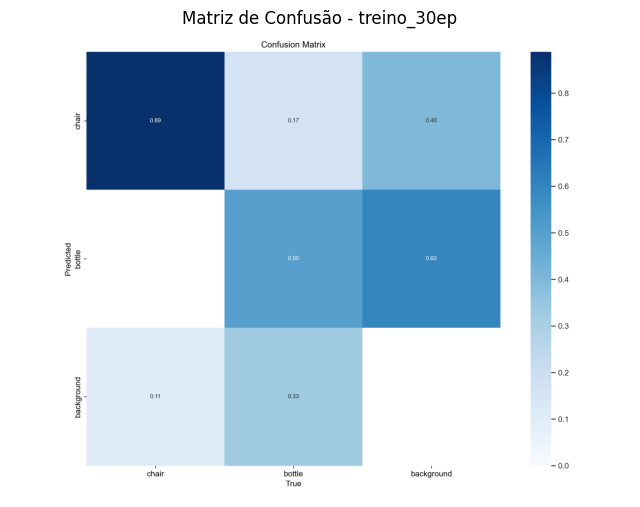

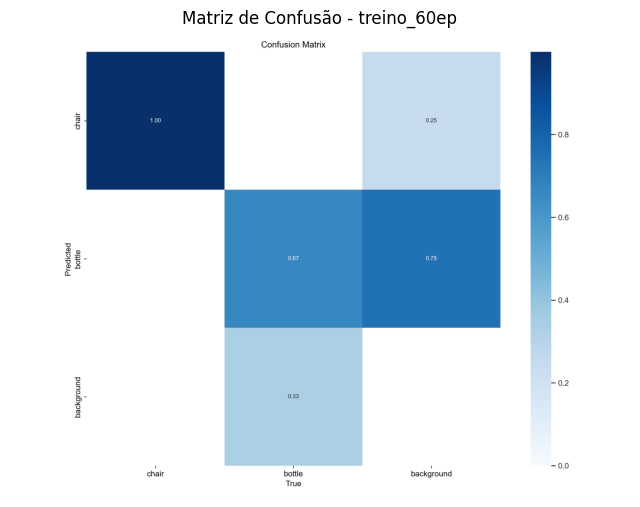

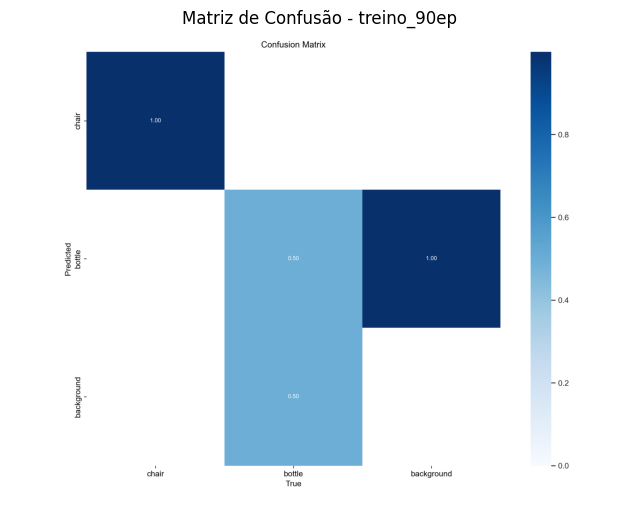

In [21]:
# Importações necessárias e definição de caminhos
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

DRIVE_DS = '/content/drive/MyDrive/Farmtech_YOLO'
RUNS_DIR = f'{DRIVE_DS}/runs'
MODELOS = ['treino_30ep', 'treino_60ep', 'treino_90ep']

# Exibe a matriz de confusão gerada pelo val.py para cada modelo no conjunto de teste separadamente
for nome in MODELOS:
    caminho = f'{RUNS_DIR}/val_test/{nome}/confusion_matrix.png'

    plt.figure(figsize=(8, 8))
    plt.imshow(mpimg.imread(caminho))
    plt.title(f'Matriz de Confusão - {nome}', fontsize=12)
    plt.axis('off')
    plt.show()

## 6. Conclusões (Entrega 1)

### Resultados obtidos no conjunto de teste

| Modelo | Precisão | Recall | mAP@0.5 | mAP@0.5:0.95 | Treino | Inferência média |
|---|---:|---:|---:|---:|---:|---:|
| 30 épocas | 0.846 | 0.620 | 0.741 | 0.358 | 2.8 min | 13.95 ms/img |
| 60 épocas | 0.974 | 0.761 | 0.828 | 0.535 | 2.6 min | 11.24 ms/img |
| 90 épocas | 0.880 | 0.744 | 0.779 | 0.492 | 3.5 min | 10.07 ms/img |

> Os valores correspondem à execução registrada neste notebook. O treinamento tem componentes aleatórios e o conjunto de teste é pequeno, então uma nova execução pode produzir números um pouco diferentes (a tendência geral tende a se manter).

### Efeito do número de épocas

De 30 para 60 épocas houve ganho em todas as métricas de teste: o `mAP@0.5` passou de 0.741 para 0.828, o `mAP@0.5:0.95` (que exige caixas mais bem ajustadas) de 0.358 para 0.535, a precisão de 0.846 para 0.974 e o recall de 0.620 para 0.761.

De 60 para 90 épocas, as quatro métricas de teste **caíram**: precisão 0.974 → 0.880, recall 0.761 → 0.744, `mAP@0.5` 0.828 → 0.779 e `mAP@0.5:0.95` 0.535 → 0.492. Na validação, ao contrário, as métricas se mantiveram ou subiram (`mAP@0.5` de 0.995 nos dois modelos e `mAP@0.5:0.95` de 0.629 para 0.715). Validação melhorando enquanto o teste piora é compatível com o início de **sobreajuste**: o modelo de 90 épocas se ajusta mais às imagens usadas no treino e na escolha do `best.pt`, e generaliza um pouco pior. Como o teste tem só 8 imagens (15 objetos), não dá para afirmar isso de forma definitiva, mas nada nos resultados indica benefício em treinar além de 60 épocas neste dataset.

### Validação e generalização

Na validação, os modelos de 60 e 90 épocas chegaram a `mAP@0.5 = 0.995`; no teste, obtiveram 0.828 e 0.779. No critério mais rigoroso (`mAP@0.5:0.95`), os valores passaram de 0.629 e 0.715 na validação para 0.535 e 0.492 no teste. A validação é usada para escolher o melhor peso (`best.pt`), por isso tende a ser otimista, e o teste mostra que o desempenho em imagens nunca vistas é inferior ao sugerido por ela. Com apenas 8 imagens em cada conjunto, poucas detecções alteram bastante os resultados.

### Desempenho por classe

A classe `chair` foi mais fácil nos três modelos: no teste, seu `mAP@0.5` foi 0.946, 0.984 e 0.995 (30, 60 e 90 épocas). A classe `bottle` ficou em 0.537, 0.672 e 0.564, com recall entre 0.500 e 0.667. As garrafas são mais finas e menores, podem ser transparentes e aparecem em poses e contextos variados, o que ajuda a explicar a dificuldade. A evolução de 30 para 60 épocas beneficiou principalmente a garrafa (`mAP@0.5:0.95` de 0.177 para 0.414); com 90 épocas, a garrafa piorou (0.314) enquanto a cadeira permaneceu estável (≈ 0.67).

### Imagens de teste processadas

Nas imagens de teste (seção 5), a `chair (40)`, uma cadeira envelhecida em foto superexposta, **não foi detectada por nenhum dos três modelos** com limiar de confiança 0.25. Na `bottle (40)` (garrafas erguidas acima da cabeça de uma pessoa), o modelo de 30 épocas não detectou nada e os de 60 e 90 épocas previram uma `chair` no lugar. O modelo de 30 épocas também produziu falsos alarmes (por exemplo, uma garrafa em `chair (38)` e uma cadeira em `bottle (38)`), que não aparecem nos modelos de 60 e 90 épocas nessas imagens.

### Tempo de treino e de inferência

O treino levou 2.8, 2.6 e 3.5 minutos (30, 60 e 90 épocas). O tempo não é proporcional às épocas: o treino de 30 épocas, o primeiro a ser executado, foi o mais demorado, provavelmente por custos de primeira execução (download dos pesos iniciais e primeira leitura do Drive). Entre 60 e 90 épocas, cada época adicional custou cerca de 2 segundos.

A inferência ficou entre 10 e 14 ms por imagem (cerca de 100 imagens por segundo na GPU T4 no melhor caso). Como a arquitetura é a mesma nas três simulações, a diferença observada provavelmente reflete a ordem das medições (o primeiro modelo medido sofre mais com o aquecimento da GPU) e não uma diferença real entre os modelos.

### Modelo selecionado

Para a continuação do trabalho foi selecionado o modelo de **60 épocas**: foi o melhor nas quatro métricas de teste (precisão 0.974, recall 0.761, `mAP@0.5` 0.828 e `mAP@0.5:0.95` 0.535) e teve o menor tempo de treino. Vale registrar que essa escolha foi feita observando o próprio conjunto de teste, o que torna a estimativa de desempenho levemente otimista; o ideal, com mais dados, seria escolher pelo conjunto de validação e reservar o teste apenas para a medição final.

### Limitações e próximos passos

- O dataset possui apenas 80 imagens, com 64 para treino, 8 para validação e 8 para teste (15 objetos no teste).
- Uma única execução foi realizada para cada quantidade de épocas; componentes aleatórios podem mudar os resultados.
- Há pouca diversidade de iluminação, ângulo, fundo, oclusão e tamanho dos objetos.
- O modelo foi escolhido com base no conjunto de teste (veja acima).
- Para melhorar a confiabilidade, recomenda-se ampliar o dataset, repetir os treinamentos, testar outros limiares de confiança e avaliar modelos maiores ou mais recentes.

A Entrega 2, apresentada a seguir, compara o melhor modelo customizado com a YOLOv3 tradicional pré-treinada e uma CNN treinada do zero.

---

# FarmTech Solutions - Comparação de Abordagens de Visão Computacional (Entrega 2)
**Grupo:** Deweyne (rm573755), Jeliel (rm572665), Denis (rm573278)

## Objetivo
Esta continuação parte da base criada na Entrega 1 e compara três abordagens:

1. **YOLO customizada da Entrega 1:** YOLOv5s ajustada (*fine-tuning*) para detectar `chair` e `bottle`.
2. **YOLO tradicional:** YOLOv3 pré-treinada em COCO, conforme o capítulo 3 de Redes Neurais, aplicada diretamente nas imagens de teste.
3. **CNN treinada do zero:** rede convolucional simples, sem pesos pré-treinados, treinada para classificar a imagem inteira como `chair` ou `bottle`.

A comparação considera facilidade de uso/integração, precisão, tempo de treinamento/customização e tempo de inferência.

> Observação conceitual: YOLO é um detector de objetos, isto é, responde **o que existe e onde está**. A CNN deste notebook é uma classificadora, isto é, responde apenas **qual é a classe principal da imagem**. Por isso, as métricas não são perfeitamente equivalentes; a comparação crítica precisa levar essa diferença em conta.


## 0. Ambiente e caminhos
O notebook espera encontrar no Google Drive a pasta `Farmtech_YOLO`, exportada da Entrega 1, com:

- `images/train`, `images/val`, `images/test`;
- `labels/train`, `labels/val`, `labels/test`;
- `runs/resumo_entrega1.csv`;
- pesos em `runs/treino_30ep`, `runs/treino_60ep` e `runs/treino_90ep`.

Se a pasta estiver em outro local, ajuste apenas a variável `DRIVE_DS`.


In [22]:
import os, glob, time, json, math, subprocess, shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# DRIVE_DS, RUNS_DIR e CLASSES são reaproveitados da Entrega 1.
DATA_YAML = '/content/data.yaml'

assert CLASSES == ['chair', 'bottle'], 'A ordem das classes deve ser 0=chair e 1=bottle.'
TEST_DIR = f'{DRIVE_DS}/images/test'
LABEL_TEST_DIR = f'{DRIVE_DS}/labels/test'
RESULTS_DIR = f'{RUNS_DIR}/entrega2'
os.makedirs(RESULTS_DIR, exist_ok=True)

print('Dataset:', DRIVE_DS)
print('Resultados Entrega 2:', RESULTS_DIR)


Dataset: /content/drive/MyDrive/Farmtech_YOLO
Resultados Entrega 2: /content/drive/MyDrive/Farmtech_YOLO/runs/entrega2


In [23]:
# Recria o data.yaml no ambiente do Colab, mantendo a mesma estrutura da Entrega 1
yaml_txt = f'''path: {DRIVE_DS}
train: images/train
val: images/val
test: images/test
nc: {len(CLASSES)}
names: {CLASSES}
'''
with open(DATA_YAML, 'w') as f:
    f.write(yaml_txt)
print(yaml_txt)


path: /content/drive/MyDrive/Farmtech_YOLO
train: images/train
val: images/val
test: images/test
nc: 2
names: ['chair', 'bottle']



## 1. Reaproveitamento dos resultados da Entrega 1
Primeiro carregamos o resumo produzido na Entrega 1. Ele será usado como a linha de base da comparação.

Entre os modelos treinados na Entrega 1, usaremos o de **60 épocas** como referência principal: no conjunto de teste ele teve o melhor resultado nas quatro métricas (precisão, recall, `mAP@0.5` e `mAP@0.5:0.95`) e o menor tempo de treino. O modelo de 90 épocas teve desempenho inferior no teste, o que sugere sobreajuste (veja as conclusões da Entrega 1). A seleção abaixo é automática, pelo `mAP@0.5:0.95` no teste.

In [24]:
resumo_entrega1 = pd.read_csv(f'{RUNS_DIR}/resumo_entrega1.csv')
resumo_entrega1


,Modelo,Precisão,Recall,mAP@0.5,mAP@0.5:0.95,Tempo de treino (min),Inferência média (ms/img),Desvio (ms)
0,treino_30ep,0.846,0.620,0.741,0.358,2.8,13.954210,1.042910
1,treino_60ep,0.974,0.761,0.828,0.535,2.6,11.238251,2.514375
2,treino_90ep,0.880,0.744,0.779,0.492,3.5,10.065364,0.492702


In [25]:
# Escolha automática do melhor modelo customizado pelo mAP@0.5:0.95 no teste
melhor_custom = resumo_entrega1.sort_values('mAP@0.5:0.95', ascending=False).iloc[0]
MELHOR_CUSTOM_NOME = melhor_custom['Modelo']
MELHOR_CUSTOM_PESO = f'{RUNS_DIR}/{MELHOR_CUSTOM_NOME}/weights/best.pt'

print('Modelo customizado escolhido:', MELHOR_CUSTOM_NOME)
print('Peso:', MELHOR_CUSTOM_PESO)
melhor_custom


Modelo customizado escolhido: treino_60ep
Peso: /content/drive/MyDrive/Farmtech_YOLO/runs/treino_60ep/weights/best.pt


,1
Modelo,treino_60ep
Precisão,0.974
Recall,0.761
mAP@0.5,0.828
mAP@0.5:0.95,0.535
Tempo de treino (min),2.6
Inferência média (ms/img),11.238251
Desvio (ms),2.514375


## 2. Funções auxiliares de avaliação
As próximas funções leem as anotações YOLO reais, convertem caixas para pixels, calculam IoU e estimam métricas de detecção.

Para a YOLO tradicional, usaremos `mAP@0.5`, precisão e recall considerando apenas as classes `chair` e `bottle`. Predições de outras classes do COCO serão ignoradas para manter a comparação no escopo do projeto.


In [26]:
def ler_ground_truth(split='test'):
    img_dir = f'{DRIVE_DS}/images/{split}'
    lbl_dir = f'{DRIVE_DS}/labels/{split}'
    gts = {}
    for img_path in sorted(glob.glob(f'{img_dir}/*')):
        nome = os.path.basename(img_path)
        base = os.path.splitext(nome)[0]
        W, H = Image.open(img_path).size
        caixas = []
        lbl_path = f'{lbl_dir}/{base}.txt'
        if os.path.exists(lbl_path):
            for linha in open(lbl_path):
                if not linha.strip():
                    continue
                cls, xc, yc, w, h = linha.split()
                cls = int(cls)
                xc, yc, w, h = map(float, (xc, yc, w, h))
                x1 = (xc - w/2) * W
                y1 = (yc - h/2) * H
                x2 = (xc + w/2) * W
                y2 = (yc + h/2) * H
                caixas.append({'class_id': cls, 'box': [x1, y1, x2, y2], 'used': False})
        gts[nome] = caixas
    return gts

def iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0

def ap_por_classe(preds, gts, class_id, iou_thr=0.5):
    preds_cls = sorted([p for p in preds if p['class_id'] == class_id], key=lambda x: x['conf'], reverse=True)
    n_gt = sum(1 for caixas in gts.values() for g in caixas if g['class_id'] == class_id)
    usado = {img: [False] * len(caixas) for img, caixas in gts.items()}
    tp, fp = [], []
    for p in preds_cls:
        caixas = gts.get(p['image'], [])
        melhor_iou, melhor_idx = 0, -1
        for idx, g in enumerate(caixas):
            if g['class_id'] != class_id or usado[p['image']][idx]:
                continue
            valor_iou = iou(p['box'], g['box'])
            if valor_iou > melhor_iou:
                melhor_iou, melhor_idx = valor_iou, idx
        if melhor_iou >= iou_thr and melhor_idx >= 0:
            tp.append(1); fp.append(0)
            usado[p['image']][melhor_idx] = True
        else:
            tp.append(0); fp.append(1)
    if n_gt == 0:
        return {'AP@0.5': np.nan, 'Precisão': np.nan, 'Recall': np.nan, 'GT': 0}
    if len(preds_cls) == 0:
        return {'AP@0.5': 0.0, 'Precisão': 0.0, 'Recall': 0.0, 'GT': n_gt}
    tp = np.cumsum(tp)
    fp = np.cumsum(fp)
    recall = tp / n_gt
    precision = tp / np.maximum(tp + fp, 1e-9)
    mrec = np.concatenate(([0.0], recall, [1.0]))
    mpre = np.concatenate(([0.0], precision, [0.0]))
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    ap = np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1])
    return {'AP@0.5': float(ap), 'Precisão': float(precision[-1]), 'Recall': float(recall[-1]), 'GT': n_gt}

def avaliar_deteccoes(preds, gts, nome_modelo):
    linhas = []
    aps = []
    total_gt = sum(len(v) for v in gts.values())
    total_tp = total_fp = 0
    for cid, cname in enumerate(CLASSES):
        met = ap_por_classe(preds, gts, cid)
        aps.append(met['AP@0.5'])
        linhas.append({'Modelo': nome_modelo, 'Classe': cname, **met})
    # métricas agregadas por casamento simples, classe a classe
    for cid in range(len(CLASSES)):
        preds_cls = sorted([p for p in preds if p['class_id'] == cid], key=lambda x: x['conf'], reverse=True)
        usado = {img: [False] * len(caixas) for img, caixas in gts.items()}
        for p in preds_cls:
            caixas = gts.get(p['image'], [])
            melhor_iou, melhor_idx = 0, -1
            for idx, g in enumerate(caixas):
                if g['class_id'] != cid or usado[p['image']][idx]:
                    continue
                valor_iou = iou(p['box'], g['box'])
                if valor_iou > melhor_iou:
                    melhor_iou, melhor_idx = valor_iou, idx
            if melhor_iou >= 0.5 and melhor_idx >= 0:
                total_tp += 1
                usado[p['image']][melhor_idx] = True
            else:
                total_fp += 1
    precisao = total_tp / max(total_tp + total_fp, 1)
    recall = total_tp / max(total_gt, 1)
    geral = {
        'Modelo': nome_modelo,
        'Classe': 'all',
        'AP@0.5': float(np.nanmean(aps)),
        'Precisão': float(precisao),
        'Recall': float(recall),
        'GT': total_gt
    }
    return pd.DataFrame([geral] + linhas)

gts_test = ler_ground_truth('test')
print('Imagens de teste:', len(gts_test))
print('Instâncias reais:', sum(len(v) for v in gts_test.values()))


Imagens de teste: 8
Instâncias reais: 15


## 3. YOLO tradicional: YOLOv3 pré-treinada em COCO
O notebook do capítulo 3 utiliza a implementação **Darknet** de Joseph Redmon (`pjreddie/darknet`) com `yolov3.cfg` e `yolov3.weights`.

Aqui usamos os mesmos pesos e arquitetura, mas com a API DNN do OpenCV para conseguir capturar as predições em formato de tabela e calcular métricas sobre o nosso conjunto de teste. Isso mantém a abordagem tradicional: **não há treinamento nem ajuste com o dataset da FarmTech**.


In [27]:
# Baixa os arquivos oficiais da YOLOv3 tradicional usados pelo Darknet
from urllib.request import Request, urlopen
import os

YOLO3_DIR = '/content/yolov3_tradicional'
os.makedirs(YOLO3_DIR, exist_ok=True)

cfg_path = f'{YOLO3_DIR}/yolov3.cfg'
weights_path = f'{YOLO3_DIR}/yolov3.weights'
names_path = f'{YOLO3_DIR}/coco.names'

downloads = {
    cfg_path: 'https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3.cfg',
    weights_path: 'https://pjreddie.com/media/files/yolov3.weights',
    names_path: 'https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names',
}

headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}

for destino, url in downloads.items():
    if not os.path.exists(destino):
        print('Baixando:', os.path.basename(destino))
        req = Request(url, headers=headers)
        with urlopen(req) as response, open(destino, 'wb') as out_file:
            out_file.write(response.read())

print('Arquivos YOLOv3 prontos.')

Baixando: yolov3.cfg
Baixando: yolov3.weights
Baixando: coco.names
Arquivos YOLOv3 prontos.


In [28]:
import cv2

print('OpenCV:', cv2.__version__)
if int(cv2.__version__.split('.')[0]) >= 5:
    raise RuntimeError(
        'O OpenCV 5 não lê arquivos Darknet. Reinicie o ambiente e execute o notebook desde o início.'
    )

coco_names = [l.strip() for l in open(names_path).read().splitlines() if l.strip()]
project_to_coco = {'chair': coco_names.index('chair'), 'bottle': coco_names.index('bottle')}
coco_to_project = {v: CLASSES.index(k) for k, v in project_to_coco.items()}
print('Mapeamento COCO -> projeto:', coco_to_project)

net = cv2.dnn.readNet(weights_path, cfg_path)
net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)  # mais robusto no Colab; OpenCV nem sempre vem compilado com CUDA

layer_names = net.getLayerNames()
output_layers = [layer_names[i - 1] for i in net.getUnconnectedOutLayers().flatten()]

def predizer_yolov3_opencv(img_path, conf_thr=0.25, nms_thr=0.45):
    img = cv2.imread(img_path)
    H, W = img.shape[:2]
    blob = cv2.dnn.blobFromImage(img, 1/255.0, (416, 416), swapRB=True, crop=False)
    net.setInput(blob)
    t0 = time.perf_counter()
    outs = net.forward(output_layers)
    elapsed = (time.perf_counter() - t0) * 1000
    boxes, confidences, class_ids = [], [], []
    for out in outs:
        for det in out:
            scores = det[5:]
            coco_id = int(np.argmax(scores))
            conf = float(scores[coco_id])
            if coco_id not in coco_to_project or conf < conf_thr:
                continue
            cx, cy, w, h = det[0:4] * np.array([W, H, W, H])
            x, y = int(cx - w/2), int(cy - h/2)
            boxes.append([x, y, int(w), int(h)])
            confidences.append(conf)
            class_ids.append(coco_to_project[coco_id])
    idxs = cv2.dnn.NMSBoxes(boxes, confidences, conf_thr, nms_thr)
    preds = []
    if len(idxs) > 0:
        for i in np.array(idxs).flatten():
            x, y, w, h = boxes[i]
            preds.append({
                'image': os.path.basename(img_path),
                'class_id': int(class_ids[i]),
                'class_name': CLASSES[int(class_ids[i])],
                'conf': float(confidences[i]),
                'box': [float(x), float(y), float(x+w), float(y+h)]
            })
    return preds, elapsed

preds_yolov3 = []
tempos_yolov3 = []
for img_path in sorted(glob.glob(f'{TEST_DIR}/*')):
    preds, ms = predizer_yolov3_opencv(img_path)
    preds_yolov3.extend(preds)
    tempos_yolov3.append(ms)

metricas_yolov3 = avaliar_deteccoes(preds_yolov3, gts_test, 'YOLOv3 tradicional')
metricas_yolov3


OpenCV: 4.10.0
Mapeamento COCO -> projeto: {56: 0, 39: 1}


,Modelo,Classe,AP@0.5,Precisão,Recall,GT
0,YOLOv3 tradicional,all,0.75,1.0,0.8,15
1,YOLOv3 tradicional,chair,1.00,1.0,1.0,9
2,YOLOv3 tradicional,bottle,0.50,1.0,0.5,6


In [29]:
tempo_yolov3_ms = float(np.mean(tempos_yolov3))
desvio_yolov3_ms = float(np.std(tempos_yolov3))

print(f'Inferência YOLOv3 tradicional: {tempo_yolov3_ms:.2f} ± {desvio_yolov3_ms:.2f} ms/imagem')
pd.DataFrame(preds_yolov3).sort_values(['image', 'class_id', 'conf'], ascending=[True, True, False]).head(20)


Inferência YOLOv3 tradicional: 1316.26 ± 667.60 ms/imagem


,image,class_id,class_name,conf,box
0,bottle (37).jpeg,1,bottle,0.992114,"[106.0, 111.0, 189.0, 446.0]"
1,bottle (37).jpeg,1,bottle,0.901885,"[121.0, 248.0, 285.0, 548.0]"
2,bottle (38).jpeg,1,bottle,0.778422,"[110.0, 37.0, 237.0, 517.0]"
3,chair (37).jpeg,0,chair,0.988741,"[130.0, 201.0, 329.0, 440.0]"
4,chair (37).jpeg,0,chair,0.985105,"[355.0, 189.0, 552.0, 450.0]"
5,chair (38).jpeg,0,chair,0.996531,"[309.0, 170.0, 505.0, 416.0]"
6,chair (38).jpeg,0,chair,0.994850,"[180.0, 137.0, 314.0, 379.0]"
7,chair (38).jpeg,0,chair,0.977978,"[14.0, 113.0, 120.0, 255.0]"
8,chair (38).jpeg,0,chair,0.967917,"[68.0, 126.0, 175.0, 277.0]"
9,chair (39).jpeg,0,chair,0.998141,"[299.0, 167.0, 448.0, 355.0]"


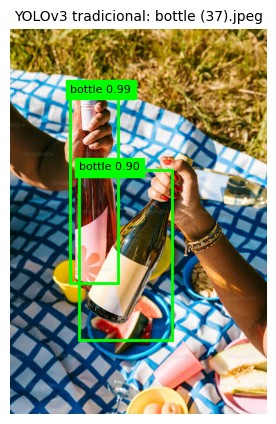

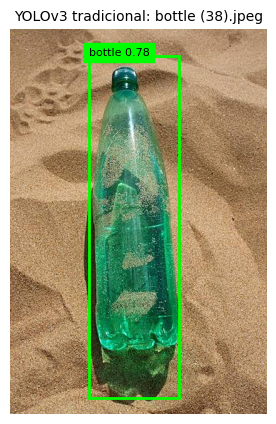

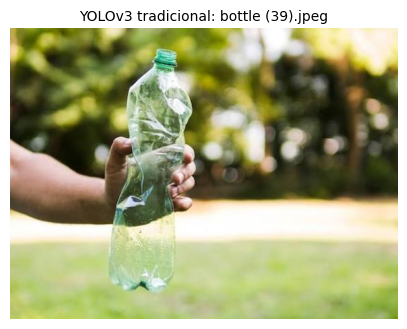

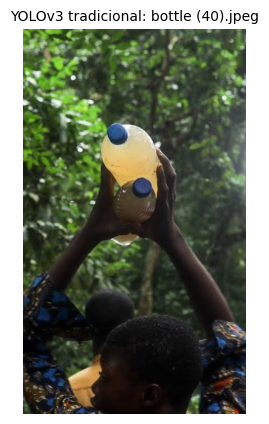

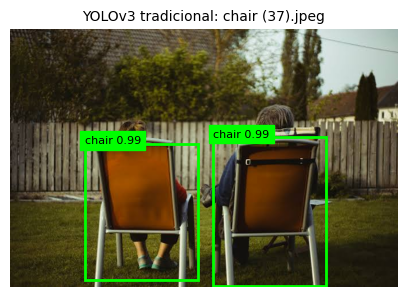

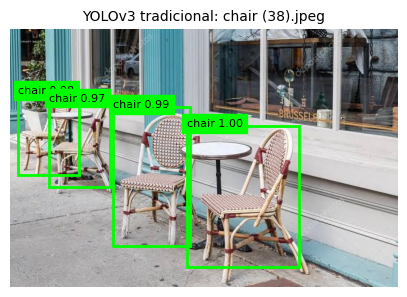

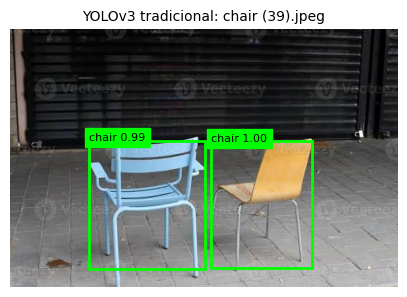

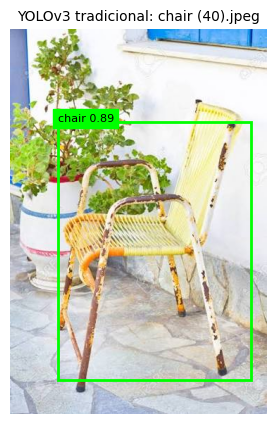

In [30]:
# Visualiza algumas predições da YOLOv3 tradicional
import matplotlib.patches as patches

def mostrar_predicoes(preds, titulo, n=8):
    preds_por_img = defaultdict(list)
    for p in preds:
        preds_por_img[p['image']].append(p)
    imgs = sorted(glob.glob(f'{TEST_DIR}/*'))[:n]
    for img_path in imgs:
        nome = os.path.basename(img_path)
        img = Image.open(img_path).convert('RGB')
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(img); ax.axis('off')
        ax.set_title(f'{titulo}: {nome}', fontsize=10)
        for p in preds_por_img[nome]:
            x1, y1, x2, y2 = p['box']
            ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor='lime', linewidth=2))
            ax.text(x1, y1, f"{p['class_name']} {p['conf']:.2f}", color='black', backgroundcolor='lime', fontsize=8)
        plt.show()

mostrar_predicoes(preds_yolov3, 'YOLOv3 tradicional')


## 4. CNN treinada do zero para classificação
A CNN abaixo não usa pesos pré-treinados. Ela aprende a partir das 64 imagens de treino e valida nas 8 imagens de validação.

Como a tarefa é classificação, cada imagem recebe uma única classe pelo nome do arquivo (`chair` ou `bottle`). As caixas dos arquivos `.txt` não são usadas nesta abordagem.


In [31]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print('TensorFlow:', tf.__version__)

IMG_SIZE = (160, 160)
BATCH_SIZE = 8
SEED = 42

def listar_imagens_classificacao(split):
    linhas = []
    for p in sorted(glob.glob(f'{DRIVE_DS}/images/{split}/*')):
        nome = os.path.basename(p)
        if nome.startswith('chair'):
            cls = 0
        elif nome.startswith('bottle'):
            cls = 1
        else:
            continue
        linhas.append({'path': p, 'label': cls, 'class_name': CLASSES[cls]})
    return pd.DataFrame(linhas)

df_train = listar_imagens_classificacao('train')
df_val = listar_imagens_classificacao('val')
df_test = listar_imagens_classificacao('test')

display(df_train['class_name'].value_counts().rename('train'))
display(df_val['class_name'].value_counts().rename('val'))
display(df_test['class_name'].value_counts().rename('test'))


TensorFlow: 2.21.0


,train
class_name,
bottle,32
chair,32


,val
class_name,
bottle,4
chair,4


,test
class_name,
bottle,4
chair,4


In [ ]:
# Confere se o TensorFlow enxerga a GPU (se não enxergar, a CNN é treinada e medida em CPU)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs visíveis para o TensorFlow:', gpus if gpus else 'nenhuma (CNN em CPU)')

In [32]:
def carregar_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def criar_dataset(df, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((df['path'].values, df['label'].values.astype('int32')))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(carregar_img, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = criar_dataset(df_train, shuffle=True)
val_ds = criar_dataset(df_val)
test_ds = criar_dataset(df_test)


In [33]:
tf.keras.utils.set_random_seed(SEED)

cnn = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.12),

    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.35),
    layers.Dense(len(CLASSES), activation='softmax')
])

cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 160, 160, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,234 (25.36 MB)

 Trainable params: 6,647,234 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
EPOCHS_CNN = 40
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
]

t0 = time.perf_counter()
hist = cnn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN, callbacks=callbacks)
tempo_treino_cnn = time.perf_counter() - t0

print(f'Tempo de treino CNN: {tempo_treino_cnn/60:.2f} min')


Epoch 1/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 0.5625 - loss: 1.3111 - val_accuracy: 0.5000 - val_loss: 0.7433
Epoch 2/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3906 - loss: 0.7290 - val_accuracy: 0.5000 - val_loss: 0.6854
Epoch 3/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4688 - loss: 0.6928 - val_accuracy: 0.5000 - val_loss: 0.6858
Epoch 4/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5625 - loss: 0.6884 - val_accuracy: 0.7500 - val_loss: 0.6677
Epoch 5/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5469 - loss: 0.6794 - val_accuracy: 0.8750 - val_loss: 0.6190
Epoch 6/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5469 - loss: 0.6508 - val_accuracy: 0.8750 - val_loss: 0.4546
Epoch 7/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5781 - loss: 0.6420 - val_accuracy: 0.8750 - val_loss: 0.4161
Epoch 8/40
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7500 - loss: 0.5502 - val_accuracy: 1.0000 - val_loss: 0.1238


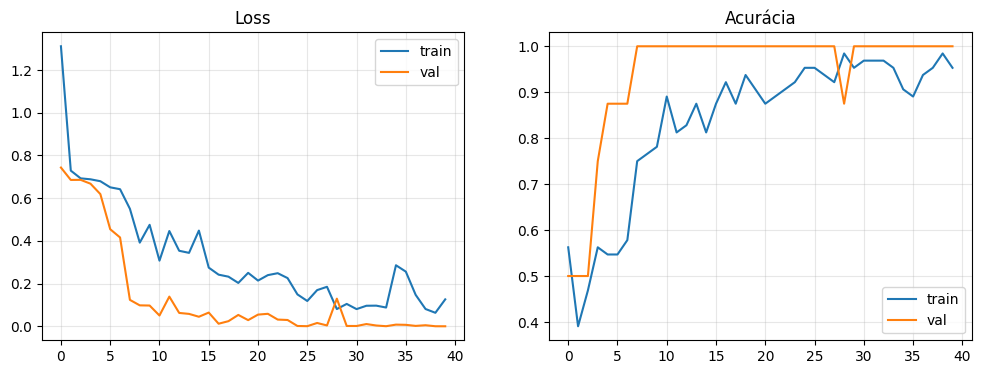

In [35]:
hist_df = pd.DataFrame(hist.history)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(hist_df['loss'], label='train')
axs[0].plot(hist_df['val_loss'], label='val')
axs[0].set_title('Loss'); axs[0].grid(alpha=.3); axs[0].legend()
axs[1].plot(hist_df['accuracy'], label='train')
axs[1].plot(hist_df['val_accuracy'], label='val')
axs[1].set_title('Acurácia'); axs[1].grid(alpha=.3); axs[1].legend()
plt.show()


In [36]:
# Avaliação da CNN no conjunto de teste
loss_test, acc_test = cnn.evaluate(test_ds, verbose=0)

# Mede tempo de inferência uma imagem por vez
imgs_test = []
labels_test = []
for path, label in zip(df_test['path'], df_test['label']):
    img, lab = carregar_img(tf.constant(path), tf.constant(label))
    imgs_test.append(img.numpy())
    labels_test.append(int(label))
imgs_test = np.stack(imgs_test)
labels_test = np.array(labels_test)

for _ in range(3):
    _ = cnn.predict(imgs_test[:1], verbose=0)

tempos_cnn = []
for img in imgs_test:
    t0 = time.perf_counter()
    _ = cnn.predict(img[None, ...], verbose=0)
    tempos_cnn.append((time.perf_counter() - t0) * 1000)

probs = cnn.predict(imgs_test, verbose=0)
pred_labels = probs.argmax(axis=1)

print(f'Acurácia teste CNN: {acc_test:.3f}')
print(f'Inferência CNN: {np.mean(tempos_cnn):.2f} ± {np.std(tempos_cnn):.2f} ms/imagem')
pd.DataFrame({
    'imagem': df_test['path'].map(os.path.basename),
    'real': [CLASSES[i] for i in labels_test],
    'predito': [CLASSES[i] for i in pred_labels],
    'confiança': probs.max(axis=1)
})


Acurácia teste CNN: 0.750
Inferência CNN: 72.74 ± 1.67 ms/imagem


,imagem,real,predito,confiança
0,bottle (37).jpeg,bottle,bottle,1.000000
1,bottle (38).jpeg,bottle,bottle,0.998927
2,bottle (39).jpeg,bottle,chair,0.989409
3,bottle (40).jpeg,bottle,bottle,1.000000
4,chair (37).jpeg,chair,bottle,1.000000
5,chair (38).jpeg,chair,chair,0.895442
6,chair (39).jpeg,chair,chair,0.998579
7,chair (40).jpeg,chair,chair,0.922298


              precision    recall  f1-score   support

       chair      0.750     0.750     0.750         4
      bottle      0.750     0.750     0.750         4

    accuracy                          0.750         8
   macro avg      0.750     0.750     0.750         8
weighted avg      0.750     0.750     0.750         8



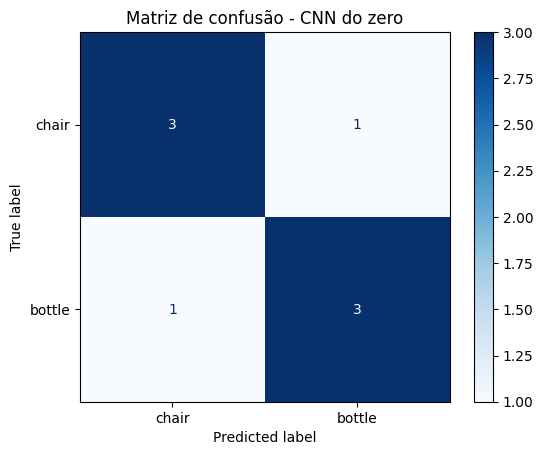

In [37]:
# Matriz de confusão da CNN
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print(classification_report(labels_test, pred_labels, target_names=CLASSES, digits=3))
cm = confusion_matrix(labels_test, pred_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES)
disp.plot(cmap='Blues')
plt.title('Matriz de confusão - CNN do zero')
plt.show()


## 5. Comparação final
Agora reunimos os resultados em uma única tabela. Para YOLO customizada e YOLO tradicional, a métrica principal de detecção é `mAP@0.5`. Para a CNN, a métrica principal é acurácia de classificação.

**Ressalvas sobre a comparação:**
- As tarefas são diferentes (detecção x classificação), então as métricas não são equivalentes.
- As métricas dos dois detectores **não foram calculadas pelo mesmo código**: as da YOLO customizada vêm do `val.py` do YOLOv5 (que avalia com limiar de confiança muito baixo e informa precisão e recall no limiar que maximiza o F1), enquanto as da YOLOv3 vêm da função própria deste notebook (que usa apenas detecções com confiança ≥ 0.25). Por isso, diferenças pequenas entre elas não são conclusivas.
- Os tempos de inferência vêm de backends diferentes: YOLO customizada em PyTorch/GPU (incluindo pré-processamento e NMS), YOLOv3 via OpenCV/CPU (apenas a passada da rede, sem aquecimento) e CNN via `model.predict` do Keras, uma imagem por vez.
- As seções **5.1** (mesmo código para os dois detectores), **5.2** (tempos padronizados) e **5.3** (quadro consolidado) refazem a comparação de forma mais justa; priorize esses números na leitura.


In [38]:
linha_custom = melhor_custom
linha_yolov3 = metricas_yolov3[metricas_yolov3['Classe'] == 'all'].iloc[0]

comparacao = pd.DataFrame([
    {
        'Abordagem': f'YOLO customizada ({MELHOR_CUSTOM_NOME})',
        'Tipo de tarefa': 'Detecção customizada',
        'Treinamento/customização': 'Sim',
        'Precisão': linha_custom['Precisão'],
        'Recall': linha_custom['Recall'],
        'mAP@0.5': linha_custom['mAP@0.5'],
        'mAP@0.5:0.95': linha_custom['mAP@0.5:0.95'],
        'Acurácia': np.nan,
        'Tempo treino/customização (min)': linha_custom['Tempo de treino (min)'],
        'Inferência média (ms/img)': linha_custom['Inferência média (ms/img)'],
        'Observação': 'Detecta classe e posição; ajustada para o dataset.'
    },
    {
        'Abordagem': 'YOLOv3 tradicional COCO',
        'Tipo de tarefa': 'Detecção pré-treinada',
        'Treinamento/customização': 'Não',
        'Precisão': linha_yolov3['Precisão'],
        'Recall': linha_yolov3['Recall'],
        'mAP@0.5': linha_yolov3['AP@0.5'],
        'mAP@0.5:0.95': np.nan,
        'Acurácia': np.nan,
        'Tempo treino/customização (min)': 0.0,
        'Inferência média (ms/img)': tempo_yolov3_ms,
        'Observação': 'Detecta classes COCO; chair e bottle já existem no COCO.'
    },
    {
        'Abordagem': 'CNN do zero',
        'Tipo de tarefa': 'Classificação',
        'Treinamento/customização': 'Sim',
        'Precisão': np.nan,
        'Recall': np.nan,
        'mAP@0.5': np.nan,
        'mAP@0.5:0.95': np.nan,
        'Acurácia': acc_test,
        'Tempo treino/customização (min)': tempo_treino_cnn / 60,
        'Inferência média (ms/img)': float(np.mean(tempos_cnn)),
        'Observação': 'Classifica a imagem inteira; não localiza objetos.'
    }
])

comparacao.to_csv(f'{RESULTS_DIR}/comparacao_entrega2.csv', index=False)
comparacao.round(3)


,Abordagem,Tipo de tarefa,Treinamento/customização,Precisão,Recall,...,mAP@0.5:0.95,Acurácia,Tempo treino/customização (min),Inferência média (ms/img),Observação
0,YOLO customizada (treino_60ep),Detecção customizada,Sim,0.974,0.761,...,0.535,NaN,2.600,11.238,Detecta classe e posição; ajustada para o data...
1,YOLOv3 tradicional COCO,Detecção pré-treinada,Não,1.000,0.800,...,NaN,NaN,0.000,1316.257,Detecta classes COCO; chair e bottle já existe...
2,CNN do zero,Classificação,Sim,NaN,NaN,...,NaN,0.75,0.319,72.743,Classifica a imagem inteira; não localiza obje...


### 5.1 Reavaliação dos detectores com o mesmo código
Na tabela anterior, as métricas da YOLO customizada vêm do `val.py` e as da YOLOv3 vêm da função própria deste notebook, que calculam coisas ligeiramente diferentes. Aqui avaliamos **os dois detectores com exatamente a mesma função** (`avaliar_deteccoes`), em dois limiares de confiança:

- **Limiar 0.001:** usado para calcular o **AP@0.5** da forma padrão (curva precisão x recall completa, sem cortar detecções de baixa confiança).
- **Limiar 0.25:** representa o uso real (só detecções com confiança ≥ 0.25 aparecem) e é onde lemos **precisão e recall**.

Nesta seção, a YOLOv3 usa a confiança do Darknet (**objectness × probabilidade da classe**) e NMS separado por classe, ao passo que a função da seção 3 usava só a probabilidade da classe. Por isso os números da YOLOv3 podem diferir dos da seção 3.

In [ ]:
import torch

# ---- YOLO customizada: predições no mesmo formato usado para a YOLOv3 (caixas em pixels: x1, y1, x2, y2) ----
yolo5 = torch.hub.load('/content/yolov5', 'custom', path=MELHOR_CUSTOM_PESO, source='local')

def predizer_yolov5_custom(conf_thr):
    # Devolve as predições da YOLO customizada em todas as imagens de teste (lista de dicts)
    yolo5.conf, yolo5.iou = conf_thr, 0.45
    preds = []
    for img_path in sorted(glob.glob(f'{TEST_DIR}/*')):
        r = yolo5(Image.open(img_path).convert('RGB'), size=640).xyxy[0].cpu().numpy()
        for x1, y1, x2, y2, cf, cl in r:
            preds.append({'image': os.path.basename(img_path), 'class_id': int(cl), 'class_name': CLASSES[int(cl)],
                          'conf': float(cf), 'box': [float(x1), float(y1), float(x2), float(y2)]})
    return preds

# ---- YOLOv3 tradicional (OpenCV): pipeline completo para uma imagem ----
def inferir_yolov3(img_bgr, conf_thr, nms_thr=0.45):
    # Pré-processamento + rede + decodificação + NMS por classe. Confiança = objectness x probabilidade da classe (como no Darknet)
    H, W = img_bgr.shape[:2]
    blob = cv2.dnn.blobFromImage(img_bgr, 1/255.0, (416, 416), swapRB=True, crop=False)
    net.setInput(blob)
    outs = net.forward(output_layers)
    boxes, confs, cids = [], [], []
    for out in outs:
        for det in out:
            scores = det[5:]
            coco_id = int(np.argmax(scores))
            if coco_id not in coco_to_project:          # ignora as outras 78 classes do COCO
                continue
            conf = float(det[4]) * float(scores[coco_id])
            if conf < conf_thr:
                continue
            cx, cy, w, h = det[0:4] * np.array([W, H, W, H])
            boxes.append([int(cx - w/2), int(cy - h/2), int(w), int(h)])
            confs.append(conf); cids.append(coco_to_project[coco_id])
    preds = []
    for cid in set(cids):                               # NMS separado para cada classe
        ids = [k for k, c in enumerate(cids) if c == cid]
        keep = cv2.dnn.NMSBoxes([boxes[k] for k in ids], [confs[k] for k in ids], conf_thr, nms_thr)
        for q in np.array(keep).flatten():
            k = ids[int(q)]; x, y, w, h = boxes[k]
            preds.append({'class_id': cid, 'class_name': CLASSES[cid], 'conf': confs[k],
                          'box': [float(x), float(y), float(x + w), float(y + h)]})
    return preds

def predizer_yolov3(conf_thr):
    # Predições da YOLOv3 em todas as imagens de teste
    preds = []
    for img_path in sorted(glob.glob(f'{TEST_DIR}/*')):
        for p in inferir_yolov3(cv2.imread(img_path), conf_thr):
            preds.append({'image': os.path.basename(img_path), **p})
    return preds

# ---- Mesma avaliação (avaliar_deteccoes) para os dois, em dois limiares de confiança ----
NOME_CUSTOM = f'YOLO customizada ({MELHOR_CUSTOM_NOME})'
linhas = []
for nome, funcao in [(NOME_CUSTOM, predizer_yolov5_custom), ('YOLOv3 tradicional', predizer_yolov3)]:
    for limiar in [0.25, 0.001]:
        preds = funcao(limiar)
        d = avaliar_deteccoes(preds, gts_test, nome).set_index('Classe')
        linhas.append({'Modelo': nome, 'Limiar de confiança': limiar,
                       'AP@0.5 (média)': d.loc['all', 'AP@0.5'], 'AP@0.5 chair': d.loc['chair', 'AP@0.5'],
                       'AP@0.5 bottle': d.loc['bottle', 'AP@0.5'],
                       'Precisão': d.loc['all', 'Precisão'], 'Recall': d.loc['all', 'Recall'], 'Nº de detecções': len(preds)})
df_justo = pd.DataFrame(linhas)
df_justo.to_csv(f'{RESULTS_DIR}/reavaliacao_mesmo_codigo.csv', index=False)
df_justo.round(3)

### 5.2 Tempos de inferência padronizados
Para os três modelos usamos o **mesmo procedimento**: imagens de teste já carregadas na memória, aquecimento, várias repetições e **uma imagem por vez**. Cada modelo roda no seu backend natural (YOLO customizada em PyTorch/GPU, YOLOv3 via OpenCV/CPU e CNN em TensorFlow), e o tempo da YOLOv3 e da YOLO customizada inclui pré-processamento, rede e pós-processamento (NMS). Na CNN, a medição é a chamada direta ao modelo (sem o overhead do `model.predict`) e **não inclui a leitura e o redimensionamento da imagem**, o que a favorece levemente.

In [ ]:
def medir(funcao, entradas, n_rep=5, aquecimento=1):
    # Tempo médio (ms/imagem) e desvio padrão: aquecimento + n_rep repetições sobre todas as imagens, uma por vez
    for _ in range(aquecimento):
        for x in entradas: funcao(x)
    medidas = []
    for _ in range(n_rep):
        t0 = time.perf_counter()
        for x in entradas: funcao(x)
        medidas.append((time.perf_counter() - t0) / len(entradas) * 1000)
    return float(np.mean(medidas)), float(np.std(medidas))

# YOLO customizada (PyTorch): sincroniza a GPU para medir o tempo real
imgs_pil_teste = [Image.open(p).convert('RGB') for p in sorted(glob.glob(f'{TEST_DIR}/*'))]
def inferir_yolo5(im):
    yolo5.conf = 0.25
    yolo5(im, size=640)
    if torch.cuda.is_available(): torch.cuda.synchronize()
t_yolo5 = medir(inferir_yolo5, imgs_pil_teste, n_rep=20, aquecimento=3)

# YOLOv3 tradicional (OpenCV, CPU): pipeline completo com limiar 0.25
imgs_bgr_teste = [cv2.imread(p) for p in sorted(glob.glob(f'{TEST_DIR}/*'))]
t_yolov3 = medir(lambda im: inferir_yolov3(im, 0.25), imgs_bgr_teste, n_rep=5, aquecimento=1)

# CNN (TensorFlow): chamada direta ao modelo, uma imagem por vez
@tf.function(reduce_retracing=True)
def prever_cnn_rapido(x):
    return cnn(x, training=False)
entradas_cnn = [tf.constant(img[None, ...]) for img in imgs_test]
t_cnn = medir(lambda x: prever_cnn_rapido(x).numpy(), entradas_cnn, n_rep=20, aquecimento=3)

print(f'YOLO customizada: {t_yolo5[0]:.2f} ± {t_yolo5[1]:.2f} ms/img')
print(f'YOLOv3 tradicional: {t_yolov3[0]:.2f} ± {t_yolov3[1]:.2f} ms/img')
print(f'CNN do zero: {t_cnn[0]:.2f} ± {t_cnn[1]:.2f} ms/img')

### 5.3 Quadro comparativo consolidado
Reúne, em uma única tabela, a reavaliação com o mesmo código (5.1), os tempos padronizados (5.2) e o treinamento/customização. O **AP@0.5** vem do limiar 0.001; **precisão e recall** vêm do limiar 0.25. A CNN só tem acurácia, pois não detecta caixas.

In [ ]:
jj = df_justo.set_index(['Modelo', 'Limiar de confiança'])
backend_cnn = 'TensorFlow / GPU' if tf.config.list_physical_devices('GPU') else 'TensorFlow / CPU'

comparacao_final = pd.DataFrame([
    {'Abordagem': NOME_CUSTOM, 'AP@0.5': jj.loc[(NOME_CUSTOM, 0.001), 'AP@0.5 (média)'],
     'Precisão (conf 0.25)': jj.loc[(NOME_CUSTOM, 0.25), 'Precisão'], 'Recall (conf 0.25)': jj.loc[(NOME_CUSTOM, 0.25), 'Recall'],
     'Acurácia (classificação)': np.nan, 'Treino/customização (min)': float(melhor_custom['Tempo de treino (min)']),
     'Inferência (ms/img)': t_yolo5[0], 'Backend': 'PyTorch / GPU'},
    {'Abordagem': 'YOLOv3 tradicional', 'AP@0.5': jj.loc[('YOLOv3 tradicional', 0.001), 'AP@0.5 (média)'],
     'Precisão (conf 0.25)': jj.loc[('YOLOv3 tradicional', 0.25), 'Precisão'], 'Recall (conf 0.25)': jj.loc[('YOLOv3 tradicional', 0.25), 'Recall'],
     'Acurácia (classificação)': np.nan, 'Treino/customização (min)': 0.0,
     'Inferência (ms/img)': t_yolov3[0], 'Backend': 'OpenCV / CPU'},
    {'Abordagem': 'CNN do zero', 'AP@0.5': np.nan, 'Precisão (conf 0.25)': np.nan, 'Recall (conf 0.25)': np.nan,
     'Acurácia (classificação)': acc_test, 'Treino/customização (min)': tempo_treino_cnn / 60,
     'Inferência (ms/img)': t_cnn[0], 'Backend': backend_cnn},
]).set_index('Abordagem')
comparacao_final.to_csv(f'{RESULTS_DIR}/comparacao_final_entrega2.csv')
comparacao_final.round(3)

> **Revisar após executar as seções 5.1 a 5.3:** os valores citados abaixo vêm da primeira execução e devem ser conferidos/atualizados com os quadros 5.1 a 5.3 (remova este aviso depois).

## 6. Análise crítica

### Facilidade de uso e integração
A **YOLO customizada** exige mais preparação: coletar e **rotular caixas** nas imagens (o trabalho manual mais pesado do projeto), criar o `data.yaml`, treinar, validar e escolher os pesos. Em troca, fica ajustada ao cenário do cliente, entrega caixas com as classes específicas do projeto e gera um modelo pequeno (7,0 milhões de parâmetros, `best.pt` de 14,4 MB).

A **YOLOv3 tradicional** é a abordagem mais rápida para começar quando as classes desejadas já existem no COCO, como ocorre com `chair` e `bottle`: não exige rotulação nem treinamento. Em contrapartida, é um modelo muito maior (cerca de 62 milhões de parâmetros e arquivo de pesos de aproximadamente 240 MB), exigiu baixar os arquivos Darknet, fixar a versão do OpenCV para conseguir lê-los e ficou limitada ao vocabulário do COCO. Se o cliente pedisse uma classe inexistente no COCO, como um objeto muito específico da fazenda, ela não resolveria sem customização.

A **CNN do zero** é simples de entender e **a mais barata de rotular** (basta a classe da imagem, que vem do nome do arquivo, sem caixas), mas muda a natureza do problema: não informa a posição do objeto. Serve quando há uma imagem com um objeto principal e a pergunta é apenas "qual classe é esta?", e é inadequada para segurança, contagem, monitoramento ou qualquer cenário que precise localizar objetos.

### Precisão e adequação das métricas
Para detecção, a métrica mais apropriada é o `mAP`, pois considera classe, confiança e sobreposição da caixa prevista com a caixa real. Para classificação, usamos acurácia, pois a CNN decide apenas entre `chair` e `bottle`.

No teste (15 objetos em 8 imagens), a **YOLO customizada (60 épocas)** teve `mAP@0.5 = 0.828` e `mAP@0.5:0.95 = 0.535`, com precisão 0.974 e recall 0.761. A **YOLOv3 tradicional**, sem nenhum treino com as nossas imagens, teve `mAP@0.5 = 0.750`, precisão 1.000 e recall 0.800 (ver ressalvas da seção 5 sobre o cálculo). Por classe, a YOLOv3 foi perfeita nas cadeiras (`AP@0.5 = 1.000`, as 9 cadeiras encontradas) e teve dificuldade em garrafas (`AP@0.5 = 0.500`, apenas 3 das 6 encontradas), enquanto a YOLO customizada teve `mAP@0.5` de 0.984 em cadeiras e 0.672 em garrafas. Ou seja, a customização trouxe ganho moderado e concentrado nas garrafas; para cadeiras, o modelo COCO pronto já era excelente. Isso é coerente com a Entrega 1: garrafas são objetos menores, finos, frequentemente transparentes ou parcialmente cobertos. Com tão poucos objetos, a diferença entre as duas (0.078 de `mAP@0.5`) corresponde a poucas detecções e não deve ser tratada como conclusiva.

A **CNN do zero** obteve acurácia de teste de `0.750`, errando 2 das 8 imagens (`bottle (39)` classificada como cadeira e `chair (37)` como garrafa), ambas com confiança acima de 0.98, ou seja, a rede erra com muita certeza. A validação chegou a 100% de acurácia com erro quase nulo, o que mostra que o conjunto de validação (8 imagens) é pequeno demais para guiar a parada antecipada: o treino rodou as 40 épocas e o resultado no teste foi bem inferior. A arquitetura também é grande para o tamanho do dataset (6,6 milhões de parâmetros para 64 imagens, quase todos na camada densa após o `Flatten`), o que favorece o sobreajuste. Esse resultado é útil como comparação, mas não substitui uma métrica de detecção porque a CNN não avalia caixas nem localização.

### Tempo de treinamento/customização
A YOLO tradicional não teve custo de treinamento neste projeto (apenas usamos pesos prontos do COCO, treinados por terceiros com um custo computacional muito maior). A YOLO customizada levou 2,6 minutos para ajustar os pesos (60 épocas), mais o tempo humano de rotular as caixas. A CNN levou cerca de 0,3 minuto (40 épocas) e não exigiu caixas, mas foi treinada do zero apenas com 64 imagens.

### Tempo de inferência
Os tempos devem ser interpretados com cuidado porque não foram medidos no mesmo backend nem com o mesmo procedimento. A YOLO customizada foi medida com PyTorch na GPU T4 (11,24 ms/imagem, incluindo pré-processamento e NMS). A YOLOv3 tradicional foi executada via OpenCV em CPU, medindo apenas a passada da rede, sem aquecimento (1316 ± 668 ms/imagem; o desvio alto indica grande variação entre imagens e execuções), pois o OpenCV 5 não lê arquivos Darknet e usamos o OpenCV 4. Esse valor mostra principalmente o custo desse backend no ambiente usado, somado ao tamanho do modelo (cerca de 9 vezes mais parâmetros que a YOLOv5s), e não uma conclusão universal de que a YOLOv3 seja sempre tão lenta.

A CNN apresentou inferência média de 72,7 ms/imagem usando `model.predict` uma imagem por vez. Esse valor inclui o overhead do Keras/TensorFlow em chamadas individuais; em uma aplicação real, poderia ser reduzido com um pipeline de inferência dedicado.

### Conclusão
Para o cenário da FarmTech, a **YOLO customizada** continua sendo a opção mais adequada: resolve a tarefa completa de detecção (classe e posição), apresentou o melhor `mAP@0.5` entre as abordagens comparáveis, é leve e rápida na GPU e pode ser estendida a classes novas apenas com novos rótulos. No entanto, o resultado mostra que, para objetos comuns como cadeiras, a **YOLOv3 tradicional** já entrega desempenho próximo sem nenhum treino, e é uma excelente linha de base e uma alternativa rápida de prototipar quando as classes existem no COCO; a vantagem da customização foi maior nas garrafas. A **CNN do zero** é útil como comparação didática e como classificador simples, mas não atende ao objetivo de visão computacional com localização de objetos e, com 64 imagens, tende a errar com muita confiança.

Como o teste tem apenas 8 imagens, essas conclusões indicam tendências, e não diferenças estatisticamente comprovadas.

## 7. Próximos passos recomendados
- Aumentar o dataset com mais variações de iluminação, distância, ângulo, oclusão e fundo.
- Repetir os treinamentos mais de uma vez para reduzir o efeito da aleatoriedade.
- Testar limiares de confiança diferentes para equilibrar falsos positivos e objetos perdidos.
- Avaliar modelos maiores ou mais recentes se o ambiente de produção permitir.
- Para a CNN, testar uma versão com mais dados ou com validação cruzada, já que o conjunto de teste tem apenas 8 imagens.
